In [1]:
import torch
import torchvision
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not enabled. Select Runtime → Change runtime type → T4 GPU.")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA version: 13.0


In [2]:
import torch
import torch.nn as nn

class PathMNISTCNN(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        return self.classifier(x)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PathMNISTCNN(num_classes=9).to(device)

dummy_input = torch.randn(64, 3, 28, 28).to(device)
output = model(dummy_input)

print("Device:", device)
print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", total_params)

targets = torch.randint(0, 9, (64,)).to(device)

loss = nn.CrossEntropyLoss()(output, targets)
loss.backward()

print("Loss:", loss.item())
print("Backward pass: Successful")
print("CNN validation: PASSED")

Device: cuda
Input shape: torch.Size([64, 3, 28, 28])
Output shape: torch.Size([64, 9])
Total parameters: 19977
Loss: 2.1852474212646484
Backward pass: Successful
CNN validation: PASSED


In [4]:
!pip install -q medmnist

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import transforms
from medmnist import PathMNIST

import random

In [6]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [8]:
from pathlib import Path

DATA_DIR = Path("/content/PathMNIST-FL/data/medmnist")

DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset directory:", DATA_DIR)
print("Directory exists:", DATA_DIR.exists())

Dataset directory: /content/PathMNIST-FL/data/medmnist
Directory exists: True


In [11]:
transform = transforms.ToTensor()

train_dataset = PathMNIST(
    split="train",
    root=DATA_DIR,
    download=True,
    transform=transform
)

val_dataset = PathMNIST(
    split="val",
    root=DATA_DIR,
    download=True,
    transform=transform
)

test_dataset = PathMNIST(
    split="test",
    root= DATA_DIR,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 206M/206M [01:05<00:00, 3.14MB/s]


Training samples: 89996
Validation samples: 10004
Testing samples: 7180


In [12]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [13]:
class PathMNISTCNN(nn.Module):

    def __init__(self, num_classes=9):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        return self.classifier(x)


model = PathMNISTCNN(num_classes=9).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01
)

print(model)

PathMNISTCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=64, out_features=9, bias=True)
)


In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.view(-1).long().to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.view(-1).long().to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [15]:
EPOCHS = 20

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch [1/20] Train Loss: 2.1734 | Train Acc: 0.1475 | Val Loss: 2.1480 | Val Acc: 0.1953
Epoch [2/20] Train Loss: 2.0319 | Train Acc: 0.2607 | Val Loss: 1.9068 | Val Acc: 0.2609
Epoch [3/20] Train Loss: 1.8283 | Train Acc: 0.3387 | Val Loss: 1.7523 | Val Acc: 0.4567
Epoch [4/20] Train Loss: 1.5808 | Train Acc: 0.4923 | Val Loss: 1.4447 | Val Acc: 0.5171
Epoch [5/20] Train Loss: 1.3521 | Train Acc: 0.5294 | Val Loss: 1.2732 | Val Acc: 0.5365
Epoch [6/20] Train Loss: 1.2627 | Train Acc: 0.5428 | Val Loss: 1.3716 | Val Acc: 0.4905
Epoch [7/20] Train Loss: 1.1976 | Train Acc: 0.5596 | Val Loss: 1.2354 | Val Acc: 0.5443
Epoch [8/20] Train Loss: 1.1559 | Train Acc: 0.5684 | Val Loss: 1.2978 | Val Acc: 0.4765
Epoch [9/20] Train Loss: 1.1155 | Train Acc: 0.5824 | Val Loss: 1.0617 | Val Acc: 0.5978
Epoch [10/20] Train Loss: 1.0715 | Train Acc: 0.6002 | Val Loss: 1.0441 | Val Acc: 0.6096
Epoch [11/20] Train Loss: 1.0372 | Train Acc: 0.6164 | Val Loss: 1.0311 | Val Acc: 0.6127
Epoch [12/20] Train

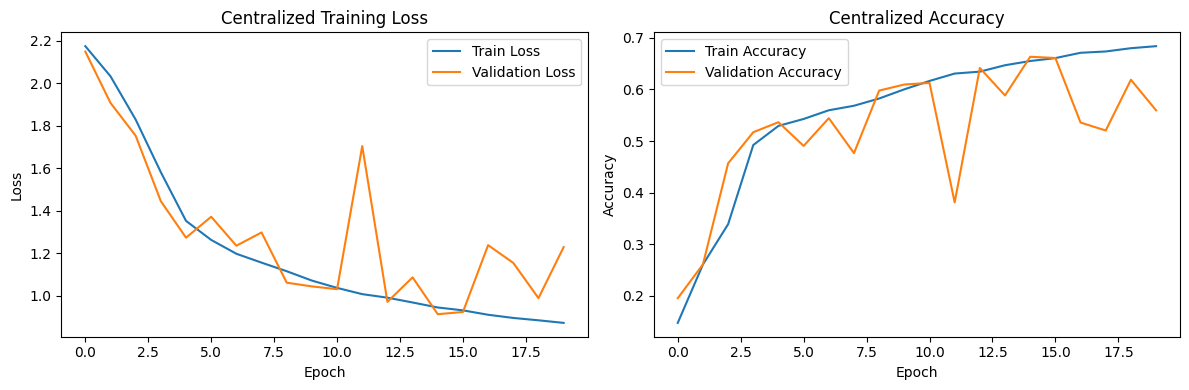

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Centralized Training Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_accuracy"], label="Train Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Centralized Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy:.4f}")

Final Test Loss: 1.2365
Final Test Accuracy: 0.6109


In [18]:
import json
import numpy as np

PARTITION_PATH = (
    "/content/pathmnist_dirichlet_alpha_0.3_seed_42.json"
)

with open(PARTITION_PATH, "r") as f:
    partition_data = json.load(f)

client_indices = {
    int(client_id): np.asarray(indices, dtype=np.int64)
    for client_id, indices
    in partition_data["client_indices"].items()
}

print("Number of clients:", len(client_indices))

for client_id, indices in client_indices.items():
    print(
        f"Client {client_id}: "
        f"{len(indices)} training samples"
    )

Number of clients: 5
Client 0: 20325 training samples
Client 1: 24231 training samples
Client 2: 13916 training samples
Client 3: 23749 training samples
Client 4: 7775 training samples


In [19]:
original_train_labels = np.asarray(
    train_dataset.labels
).reshape(-1).astype(np.int64)

print("Training labels shape:", original_train_labels.shape)
print("Unique classes:", np.unique(original_train_labels))
print("Number of classes:", len(np.unique(original_train_labels)))

assert len(original_train_labels) == 89996
assert len(np.unique(original_train_labels)) == 9

Training labels shape: (89996,)
Unique classes: [0 1 2 3 4 5 6 7 8]
Number of classes: 9


In [20]:
def inject_symmetric_label_noise(
    labels,
    noise_rate=0.4,
    num_classes=9,
    seed=42
):
    labels = np.asarray(labels).reshape(-1).astype(np.int64)

    if not 0 <= noise_rate <= 1:
        raise ValueError("noise_rate must be between 0 and 1")

    if np.any(labels < 0) or np.any(labels >= num_classes):
        raise ValueError("Labels contain invalid class values")

    rng = np.random.default_rng(seed)

    noisy_labels = labels.copy()

    num_noisy = int(round(noise_rate * len(labels)))

    noisy_indices = rng.choice(
        len(labels),
        size=num_noisy,
        replace=False
    )

    noise_mask = np.zeros(len(labels), dtype=bool)
    noise_mask[noisy_indices] = True

    # Generate a non-zero offset to guarantee a different class.
    offsets = rng.integers(
        1,
        num_classes,
        size=num_noisy
    )

    noisy_labels[noisy_indices] = (
        labels[noisy_indices] + offsets
    ) % num_classes

    return noisy_labels, noise_mask

In [21]:
NUM_CLIENTS = 5
NOISY_CLIENT_ID = 0
NOISE_RATE = 0.40
NUM_CLASSES = 9
SEED = 42

client_clean_labels = {}
client_train_labels = {}
client_noise_masks = {}

for client_id, indices in client_indices.items():

    clean_labels = original_train_labels[indices].copy()

    if client_id == NOISY_CLIENT_ID:

        train_labels, noise_mask = inject_symmetric_label_noise(
            labels=clean_labels,
            noise_rate=NOISE_RATE,
            num_classes=NUM_CLASSES,
            seed=SEED
        )

    else:

        train_labels = clean_labels.copy()

        noise_mask = np.zeros(
            len(clean_labels),
            dtype=bool
        )

    client_clean_labels[client_id] = clean_labels
    client_train_labels[client_id] = train_labels
    client_noise_masks[client_id] = noise_mask

print("Client-specific label preparation completed.")

Client-specific label preparation completed.


In [22]:
print("=" * 55)
print("CLIENT LABEL NOISE VALIDATION")
print("=" * 55)

for client_id in range(NUM_CLIENTS):

    clean = client_clean_labels[client_id]
    noisy = client_train_labels[client_id]
    mask = client_noise_masks[client_id]

    actual_changes = np.sum(clean != noisy)
    expected_changes = int(round(NOISE_RATE * len(clean))) if client_id == 0 else 0

    assert np.array_equal(clean != noisy, mask)

    if client_id == NOISY_CLIENT_ID:

        actual_rate = actual_changes / len(clean)

        print(f"\nClient {client_id}: NOISY")
        print("Total samples:", len(clean))
        print("Expected corrupted:", expected_changes)
        print("Actual corrupted:", actual_changes)
        print(f"Actual noise rate: {actual_rate:.4%}")

        assert actual_changes == expected_changes
        assert np.isclose(actual_rate, NOISE_RATE)

    else:

        print(f"\nClient {client_id}: CLEAN")
        print("Total samples:", len(clean))
        print("Corrupted labels:", actual_changes)

        assert actual_changes == 0

print("\nAll label-noise validation checks passed.")

CLIENT LABEL NOISE VALIDATION

Client 0: NOISY
Total samples: 20325
Expected corrupted: 8130
Actual corrupted: 8130
Actual noise rate: 40.0000%

Client 1: CLEAN
Total samples: 24231
Corrupted labels: 0

Client 2: CLEAN
Total samples: 13916
Corrupted labels: 0

Client 3: CLEAN
Total samples: 23749
Corrupted labels: 0

Client 4: CLEAN
Total samples: 7775
Corrupted labels: 0

All label-noise validation checks passed.


In [23]:
import os

ARTIFACT_DIR = "/content/PathMNIST-FL/artifacts"

os.makedirs(ARTIFACT_DIR, exist_ok=True)

np.savez_compressed(
    os.path.join(ARTIFACT_DIR, "client_label_artifacts.npz"),

    **{
        f"client_{i}_clean": client_clean_labels[i]
        for i in range(NUM_CLIENTS)
    },

    **{
        f"client_{i}_train": client_train_labels[i]
        for i in range(NUM_CLIENTS)
    },

    **{
        f"client_{i}_noise_mask": client_noise_masks[i]
        for i in range(NUM_CLIENTS)
    }
)

print("Client label artifacts saved.")

Client label artifacts saved.


In [24]:
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np


class ClientPathMNISTDataset(Dataset):

    def __init__(self, base_dataset, indices, labels):

        self.base_dataset = base_dataset

        self.indices = np.asarray(indices, dtype=np.int64)
        self.labels = np.asarray(labels, dtype=np.int64)

        assert len(self.indices) == len(self.labels)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):

        original_index = self.indices[index]

        image, _ = self.base_dataset[original_index]

        label = int(self.labels[index])

        return image, torch.tensor(label, dtype=torch.long)

In [25]:
NUM_CLIENTS = 5
BATCH_SIZE = 64

client_datasets = {}
client_loaders = {}

for client_id in range(NUM_CLIENTS):

    dataset = ClientPathMNISTDataset(
        base_dataset=train_dataset,
        indices=client_indices[client_id],
        labels=client_train_labels[client_id]
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    client_datasets[client_id] = dataset
    client_loaders[client_id] = loader

print("Client DataLoaders created successfully.")

Client DataLoaders created successfully.


In [26]:
print("=" * 55)
print("CLIENT LABEL VERIFICATION")
print("=" * 55)

for client_id in range(NUM_CLIENTS):

    images, labels = next(iter(client_loaders[client_id]))

    print(f"\nClient {client_id}")
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Unique labels in batch:", torch.unique(labels).tolist())

    assert images.shape[1:] == (3, 28, 28)
    assert labels.ndim == 1
    assert labels.min() >= 0
    assert labels.max() < 9

print("\nClient label verification: PASSED")

CLIENT LABEL VERIFICATION

Client 0
Image batch shape: torch.Size([64, 3, 28, 28])
Label batch shape: torch.Size([64])
Unique labels in batch: [0, 1, 2, 3, 4, 5, 6, 7, 8]

Client 1
Image batch shape: torch.Size([64, 3, 28, 28])
Label batch shape: torch.Size([64])
Unique labels in batch: [0, 1, 2, 6, 8]

Client 2
Image batch shape: torch.Size([64, 3, 28, 28])
Label batch shape: torch.Size([64])
Unique labels in batch: [0, 1, 3, 7]

Client 3
Image batch shape: torch.Size([64, 3, 28, 28])
Label batch shape: torch.Size([64])
Unique labels in batch: [0, 4, 6, 8]

Client 4
Image batch shape: torch.Size([64, 3, 28, 28])
Label batch shape: torch.Size([64])
Unique labels in batch: [0, 1, 2, 3, 4, 5, 7, 8]

Client label verification: PASSED


In [27]:
for client_id in range(NUM_CLIENTS):

    dataset = client_datasets[client_id]

    sample_count = min(100, len(dataset))

    for i in range(sample_count):

        _, returned_label = dataset[i]

        expected_label = client_train_labels[client_id][i]

        assert returned_label.item() == expected_label

print("Client-specific training labels verified successfully.")

Client-specific training labels verified successfully.


In [28]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim


def train_client(
    global_model,
    train_loader,
    device,
    algorithm="fedavg",
    local_epochs=2,
    learning_rate=0.01,
    mu=0.01
):

    if algorithm not in ["fedavg", "fedprox"]:
        raise ValueError("Unsupported algorithm")

    # Create an independent local copy of the global model.
    local_model = copy.deepcopy(global_model).to(device)

    # Preserve the global parameters for FedProx.
    global_parameters = [
        parameter.detach().clone()
        for parameter in global_model.parameters()
    ]

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        local_model.parameters(),
        lr=learning_rate
    )

    total_classification_loss = 0.0
    total_objective_loss = 0.0
    total_samples = 0

    for epoch in range(local_epochs):

        local_model.train()

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()

            outputs = local_model(images)

            classification_loss = criterion(outputs, labels)

            if algorithm == "fedprox":

                proximal_term = torch.zeros(
                    (),
                    device=device
                )

                for local_parameter, global_parameter in zip(
                    local_model.parameters(),
                    global_parameters
                ):

                    proximal_term += torch.sum(
                        (local_parameter - global_parameter) ** 2
                    )

                objective_loss = (
                    classification_loss
                    + (mu / 2) * proximal_term
                )

            else:

                objective_loss = classification_loss

            objective_loss.backward()

            optimizer.step()

            batch_size = images.size(0)

            total_classification_loss += (
                classification_loss.item() * batch_size
            )

            total_objective_loss += (
                objective_loss.item() * batch_size
            )

            total_samples += batch_size

    average_classification_loss = (
        total_classification_loss / total_samples
    )

    average_objective_loss = (
        total_objective_loss / total_samples
    )

    return {
        "model": local_model,
        "classification_loss": average_classification_loss,
        "objective_loss": average_objective_loss
    }

In [29]:
LOCAL_EPOCHS = 2
LEARNING_RATE = 0.01
MU = 0.01

global_model = PathMNISTCNN(num_classes=9).to(device)

initial_parameters = {
    key: value.detach().clone()
    for key, value in global_model.state_dict().items()
}

fedavg_result = train_client(
    global_model=global_model,
    train_loader=client_loaders[0],
    device=device,
    algorithm="fedavg",
    local_epochs=LOCAL_EPOCHS,
    learning_rate=LEARNING_RATE
)

print("FedAvg local training completed.")
print(
    "Classification loss:",
    fedavg_result["classification_loss"]
)
print(
    "Objective loss:",
    fedavg_result["objective_loss"]
)

FedAvg local training completed.
Classification loss: 1.9712805939307219
Objective loss: 1.9712805939307219


In [30]:
fedprox_result = train_client(
    global_model=global_model,
    train_loader=client_loaders[0],
    device=device,
    algorithm="fedprox",
    local_epochs=LOCAL_EPOCHS,
    learning_rate=LEARNING_RATE,
    mu=MU
)

print("FedProx local training completed.")
print(
    "Classification loss:",
    fedprox_result["classification_loss"]
)
print(
    "Objective loss:",
    fedprox_result["objective_loss"]
)

FedProx local training completed.
Classification loss: 1.9697714502198522
Objective loss: 1.9710070535822841


In [31]:
for key, value in global_model.state_dict().items():

    assert torch.equal(
        value,
        initial_parameters[key]
    ), f"Global model unexpectedly changed: {key}"

print("Global model isolation: PASSED")

Global model isolation: PASSED


In [32]:
def models_are_different(model_a, model_b):

    for parameter_a, parameter_b in zip(
        model_a.parameters(),
        model_b.parameters()
    ):

        if not torch.equal(parameter_a, parameter_b):
            return True

    return False


assert models_are_different(
    global_model,
    fedavg_result["model"]
)

assert models_are_different(
    global_model,
    fedprox_result["model"]
)

print("Local model updates: PASSED")

Local model updates: PASSED


In [33]:
import copy

def fedavg_aggregation(client_results, client_indices):

    total_samples = sum(
        len(client_indices[client_id])
        for client_id in client_results
    )

    global_state = {}

    for key in client_results[0]["model"].state_dict():

        global_state[key] = torch.zeros_like(
            client_results[0]["model"].state_dict()[key]
        )

        for client_id, result in client_results.items():

            client_weight = (
                len(client_indices[client_id]) / total_samples
            )

            client_parameter = (
                result["model"].state_dict()[key]
            )

            global_state[key] += (
                client_weight * client_parameter
            )

    return global_state

In [34]:
client_results = {}

for client_id in range(NUM_CLIENTS):

    result = train_client(
        global_model=global_model,
        train_loader=client_loaders[client_id],
        device=device,
        algorithm="fedavg",
        local_epochs=2,
        learning_rate=0.01
    )

    client_results[client_id] = result

    print(
        f"Client {client_id} completed | "
        f"Classification loss: "
        f"{result['classification_loss']:.4f}"
    )

Client 0 completed | Classification loss: 1.9698
Client 1 completed | Classification loss: 1.6229
Client 2 completed | Classification loss: 1.2922
Client 3 completed | Classification loss: 1.4086
Client 4 completed | Classification loss: 1.7436


In [35]:
aggregated_state = fedavg_aggregation(
    client_results,
    client_indices
)

print("FedAvg aggregation completed.")

FedAvg aggregation completed.


In [36]:
new_global_model = PathMNISTCNN(num_classes=9).to(device)

new_global_model.load_state_dict(aggregated_state)

print("Global model successfully updated.")

Global model successfully updated.


In [37]:
criterion = nn.CrossEntropyLoss()

global_val_loss, global_val_accuracy = evaluate(
    new_global_model,
    val_loader,
    criterion,
    device
)

print("Global Validation Loss:", global_val_loss)
print("Global Validation Accuracy:", global_val_accuracy)

Global Validation Loss: 2.229733188931154
Global Validation Accuracy: 0.1050579768092763


In [38]:
total_samples = sum(
    len(client_indices[i])
    for i in range(NUM_CLIENTS)
)

weights = {
    i: len(client_indices[i]) / total_samples
    for i in range(NUM_CLIENTS)
}

print("Client aggregation weights:")

for client_id, weight in weights.items():
    print(f"Client {client_id}: {weight:.6f}")

print("Sum of weights:", sum(weights.values()))

assert abs(sum(weights.values()) - 1.0) < 1e-10

print("Aggregation weight validation: PASSED")

Client aggregation weights:
Client 0: 0.225843
Client 1: 0.269245
Client 2: 0.154629
Client 3: 0.263890
Client 4: 0.086393
Sum of weights: 1.0
Aggregation weight validation: PASSED


In [39]:
initial_loss, initial_accuracy = evaluate(
    global_model, val_loader, criterion, device
)

print("Initial Validation Loss:", initial_loss)
print("Initial Validation Accuracy:", initial_accuracy)

Initial Validation Loss: 2.218052186474043
Initial Validation Accuracy: 0.08896441423430627


In [40]:
manual_weight = torch.zeros_like(
    client_results[0]["model"].state_dict()["classifier.weight"]
)

total_samples = sum(len(client_indices[cid]) for cid in client_results)

for cid, result in client_results.items():
    weight = len(client_indices[cid]) / total_samples
    manual_weight += weight * result["model"].state_dict()["classifier.weight"]

difference = torch.max(
    torch.abs(manual_weight - aggregated_state["classifier.weight"])
).item()

print("Maximum aggregation difference:", difference)

Maximum aggregation difference: 0.0


In [41]:
for cid, result in client_results.items():
    squared_difference = 0.0

    for key, initial_param in global_model.state_dict().items():
        local_param = result["model"].state_dict()[key]
        squared_difference += torch.sum(
            (local_param - initial_param) ** 2
        ).item()

    print(f"Client {cid}: Parameter difference = {squared_difference ** 0.5:.6f}")

Client 0: Parameter difference = 0.561521
Client 1: Parameter difference = 1.180095
Client 2: Parameter difference = 0.993477
Client 3: Parameter difference = 1.192778
Client 4: Parameter difference = 0.712345


In [42]:
for cid, result in client_results.items():
    loss, accuracy = evaluate(
        result["model"], val_loader, criterion, device
    )

    print(
        f"Client {cid}: "
        f"Validation Loss = {loss:.4f}, "
        f"Validation Accuracy = {accuracy:.4f}"
    )

Client 0: Validation Loss = 2.3848, Validation Accuracy = 0.1409
Client 1: Validation Loss = 3.3194, Validation Accuracy = 0.1738
Client 2: Validation Loss = 3.5434, Validation Accuracy = 0.1045
Client 3: Validation Loss = 4.1564, Validation Accuracy = 0.0890
Client 4: Validation Loss = 2.6790, Validation Accuracy = 0.1353


In [43]:
import copy
import torch
import torch.nn.functional as F

# Configuration
NUM_CLIENTS = 5
LOCAL_EPOCHS = 2
LEARNING_RATE = 0.01

# Preserve the global model before this communication round
round_start_model = copy.deepcopy(global_model)

# Store local training results
round_client_results = {}

print("Starting FedAvg Communication Round 1\n")

# --------------------------------------------------
# 1. Local training on all five clients
# --------------------------------------------------

for cid in range(NUM_CLIENTS):

    print(f"Training Client {cid}...")

    result = train_client(
        global_model=round_start_model,
        train_loader=client_loaders[cid],
        device=device,
        algorithm="fedavg",
        local_epochs=LOCAL_EPOCHS,
        learning_rate=LEARNING_RATE
    )

    round_client_results[cid] = result

    print(
        f"Client {cid} | "
        f"Loss: {result['classification_loss']:.4f}"
    )

# --------------------------------------------------
# 2. Server-side weighted aggregation
# --------------------------------------------------

aggregated_state = fedavg_aggregation(
    round_client_results,
    client_indices
)

# --------------------------------------------------
# 3. Calculate client update norms and cosine
# --------------------------------------------------

client_deltas = {}

for cid, result in round_client_results.items():

    local_model = result["model"]

    delta = torch.cat([
        (local_param.detach() - global_param.detach()).reshape(-1)
        for local_param, global_param in zip(
            local_model.parameters(),
            round_start_model.parameters()
        )
    ])

    client_deltas[cid] = delta

# Weighted aggregate update
total_samples = sum(
    len(client_indices[cid])
    for cid in range(NUM_CLIENTS)
)

aggregate_delta = torch.zeros_like(
    client_deltas[0]
)

for cid in range(NUM_CLIENTS):

    weight = len(client_indices[cid]) / total_samples

    aggregate_delta += weight * client_deltas[cid]

aggregate_norm = torch.norm(aggregate_delta).item()

print("\nClient Update Diagnostics")

client_diagnostics = {}

for cid in range(NUM_CLIENTS):

    delta = client_deltas[cid]

    update_norm = torch.norm(delta).item()

    denominator = (
        torch.norm(delta) * torch.norm(aggregate_delta)
    )

    if denominator.item() > 0:
        cosine = F.cosine_similarity(
            delta.unsqueeze(0),
            aggregate_delta.unsqueeze(0)
        ).item()
    else:
        cosine = float("nan")

    client_diagnostics[cid] = {
        "update_norm": update_norm,
        "cosine_similarity": cosine
    }

    print(
        f"Client {cid} | "
        f"Update Norm: {update_norm:.6f} | "
        f"Cosine Similarity: {cosine:.6f}"
    )

print(f"\nAggregate Update Norm: {aggregate_norm:.6f}")

# --------------------------------------------------
# 4. Update global model
# --------------------------------------------------

global_model.load_state_dict(aggregated_state)

# --------------------------------------------------
# 5. Evaluate updated global model
# --------------------------------------------------

global_val_loss, global_val_accuracy = evaluate(
    global_model,
    val_loader,
    criterion,
    device
)

print("\nFedAvg Round 1 Results")
print("----------------------")
print(f"Global Validation Loss: {global_val_loss:.4f}")
print(f"Global Validation Accuracy: {global_val_accuracy:.4f}")

Starting FedAvg Communication Round 1

Training Client 0...
Client 0 | Loss: 1.9704
Training Client 1...
Client 1 | Loss: 1.6232
Training Client 2...
Client 2 | Loss: 1.2922
Training Client 3...
Client 3 | Loss: 1.4089
Training Client 4...
Client 4 | Loss: 1.7426

Client Update Diagnostics
Client 0 | Update Norm: 0.551262 | Cosine Similarity: 0.389341
Client 1 | Update Norm: 1.205407 | Cosine Similarity: 0.747697
Client 2 | Update Norm: 0.980602 | Cosine Similarity: 0.398618
Client 3 | Update Norm: 1.181252 | Cosine Similarity: 0.689723
Client 4 | Update Norm: 0.711216 | Cosine Similarity: 0.412952

Aggregate Update Norm: 0.591954

FedAvg Round 1 Results
----------------------
Global Validation Loss: 2.2323
Global Validation Accuracy: 0.1050


In [44]:
print("Test-related variables in current notebook:")

for name in sorted(globals()):
    if "test" in name.lower() or "client" in name.lower():
        obj = globals()[name]

        if isinstance(obj, (dict, list, tuple)):
            print(f"{name}: {type(obj).__name__}, length={len(obj)}")

Test-related variables in current notebook:
client_clean_labels: dict, length=5
client_datasets: dict, length=5
client_deltas: dict, length=5
client_diagnostics: dict, length=5
client_indices: dict, length=5
client_loaders: dict, length=5
client_noise_masks: dict, length=5
client_results: dict, length=5
client_train_labels: dict, length=5
round_client_results: dict, length=5


In [45]:
print("client_test_loaders exists:",
      "client_test_loaders" in globals())

if "client_test_loaders" in globals():
    for cid, loader in client_test_loaders.items():
        print(f"Client {cid}: {len(loader.dataset)} test samples")

client_test_loaders exists: False


In [46]:
import numpy as np

# Configuration
NUM_CLIENTS = 5
ALPHA = 0.3
TEST_PARTITION_SEED = 43

rng = np.random.default_rng(TEST_PARTITION_SEED)

# Extract clean labels from official test dataset
test_labels = np.asarray(test_dataset.labels).reshape(-1)

num_classes = 9
client_test_indices = {cid: [] for cid in range(NUM_CLIENTS)}

# Class-wise Dirichlet partition
for class_id in range(num_classes):

    class_indices = np.where(test_labels == class_id)[0]
    rng.shuffle(class_indices)

    proportions = rng.dirichlet(
        np.repeat(ALPHA, NUM_CLIENTS)
    )

    split_points = (
        np.cumsum(proportions)[:-1] * len(class_indices)
    ).astype(int)

    client_splits = np.split(class_indices, split_points)

    for cid, indices in enumerate(client_splits):
        client_test_indices[cid].extend(indices.tolist())

# Shuffle each client's assigned indices
for cid in range(NUM_CLIENTS):
    rng.shuffle(client_test_indices[cid])

# Validation
all_test_indices = [
    idx
    for indices in client_test_indices.values()
    for idx in indices
]

assert len(all_test_indices) == len(test_dataset)
assert len(set(all_test_indices)) == len(test_dataset)
assert min(all_test_indices) == 0
assert max(all_test_indices) < len(test_dataset)

print("Test partition created successfully.")
print("Total test samples:", len(all_test_indices))

for cid in range(NUM_CLIENTS):
    print(
        f"Client {cid}: "
        f"{len(client_test_indices[cid])} samples"
    )

Test partition created successfully.
Total test samples: 7180
Client 0: 2080 samples
Client 1: 791 samples
Client 2: 1915 samples
Client 3: 1724 samples
Client 4: 670 samples


In [47]:
from torch.utils.data import DataLoader, Subset

client_test_loaders = {}

for cid in range(NUM_CLIENTS):

    client_test_dataset = Subset(
        test_dataset,
        client_test_indices[cid]
    )

    client_test_loaders[cid] = DataLoader(
        client_test_dataset,
        batch_size=64,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

print("\nClient test DataLoaders created.")

for cid, loader in client_test_loaders.items():
    print(
        f"Client {cid}: "
        f"{len(loader.dataset)} samples | "
        f"{len(loader)} batches"
    )


Client test DataLoaders created.
Client 0: 2080 samples | 33 batches
Client 1: 791 samples | 13 batches
Client 2: 1915 samples | 30 batches
Client 3: 1724 samples | 27 batches
Client 4: 670 samples | 11 batches


In [48]:
for cid, loader in client_test_loaders.items():

    for images, labels in loader:

        labels = labels.view(-1).long()

        assert torch.all(
            (labels >= 0) & (labels < 9)
        )

print("All client test labels are valid and clean.")

All client test labels are valid and clean.


In [49]:
import copy
import random
import numpy as np
import torch

# Reproducibility seed
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Create a completely fresh model
set_seed(SEED)

initial_model = PathMNISTCNN(num_classes=9).to(device)

# Preserve its initial parameters
initial_state = {
    key: value.detach().clone()
    for key, value in initial_model.state_dict().items()
}

print("Fresh initialization created.")
print("Total parameters:", sum(
    p.numel() for p in initial_model.parameters()
))

# Verify state is preserved
verification_model = PathMNISTCNN(num_classes=9).to(device)
verification_model.load_state_dict(initial_state)

for key, value in verification_model.state_dict().items():
    assert torch.equal(value, initial_state[key])

print("Initial model state verification: PASSED")

Fresh initialization created.
Total parameters: 19977
Initial model state verification: PASSED


In [50]:
import copy
import torch
import torch.nn.functional as F

def run_federated_experiment(
    algorithm,
    initial_state,
    rounds=1,
    local_epochs=2,
    learning_rate=0.01,
    mu=0.01,
    seed=42
):

    if algorithm not in ["fedavg", "fedprox"]:
        raise ValueError("Algorithm must be fedavg or fedprox")

    # Reset random generators for a reproducible comparison
    set_seed(seed)

    # Fresh global model initialized from the common state
    server_model = PathMNISTCNN(num_classes=9).to(device)
    server_model.load_state_dict(copy.deepcopy(initial_state))

    history = []

    print(f"\nStarting {algorithm.upper()} experiment")
    print(f"Communication rounds: {rounds}")

    for round_num in range(1, rounds + 1):

        print(f"\n{'=' * 45}")
        print(f"{algorithm.upper()} | Round {round_num}")
        print(f"{'=' * 45}")

        # Preserve the global model at the beginning of the round
        round_start_model = copy.deepcopy(server_model)

        client_results = {}

        # -----------------------------------------
        # 1. Client-side local training
        # -----------------------------------------

        for cid in range(NUM_CLIENTS):

            result = train_client(
                global_model=round_start_model,
                train_loader=client_loaders[cid],
                device=device,
                algorithm=algorithm,
                local_epochs=local_epochs,
                learning_rate=learning_rate,
                mu=mu
            )

            client_results[cid] = result

            print(
                f"Client {cid} | "
                f"Classification Loss: "
                f"{result['classification_loss']:.4f}"
            )

        # -----------------------------------------
        # 2. Server-side weighted aggregation
        # -----------------------------------------

        aggregated_state = fedavg_aggregation(
            client_results,
            client_indices
        )

        # -----------------------------------------
        # 3. Calculate client update vectors
        # -----------------------------------------

        client_deltas = {}

        for cid, result in client_results.items():

            local_model = result["model"]

            delta = torch.cat([
                (
                    local_param.detach()
                    - global_param.detach()
                ).reshape(-1)

                for local_param, global_param in zip(
                    local_model.parameters(),
                    round_start_model.parameters()
                )
            ])

            client_deltas[cid] = delta

        # -----------------------------------------
        # 4. Calculate aggregate update vector
        # -----------------------------------------

        total_samples = sum(
            len(client_indices[cid])
            for cid in range(NUM_CLIENTS)
        )

        aggregate_delta = torch.zeros_like(
            client_deltas[0]
        )

        for cid in range(NUM_CLIENTS):

            weight = (
                len(client_indices[cid]) / total_samples
            )

            aggregate_delta += weight * client_deltas[cid]

        # -----------------------------------------
        # 5. Update norms and cosine similarities
        # -----------------------------------------

        diagnostics = {}

        for cid in range(NUM_CLIENTS):

            delta = client_deltas[cid]

            update_norm = torch.norm(delta).item()

            denominator = (
                torch.norm(delta) *
                torch.norm(aggregate_delta)
            )

            if denominator.item() > 0:

                cosine = F.cosine_similarity(
                    delta.unsqueeze(0),
                    aggregate_delta.unsqueeze(0)
                ).item()

            else:
                cosine = float("nan")

            diagnostics[cid] = {
                "update_norm": update_norm,
                "cosine_similarity": cosine
            }

        # -----------------------------------------
        # 6. Update global model
        # -----------------------------------------

        server_model.load_state_dict(aggregated_state)

        # -----------------------------------------
        # 7. Global validation evaluation
        # -----------------------------------------

        global_val_loss, global_val_accuracy = evaluate(
            server_model,
            val_loader,
            criterion,
            device
        )

        # -----------------------------------------
        # 8. Per-client clean test evaluation
        # -----------------------------------------

        client_test_metrics = {}

        for cid in range(NUM_CLIENTS):

            test_loss, test_accuracy = evaluate(
                server_model,
                client_test_loaders[cid],
                criterion,
                device
            )

            client_test_metrics[cid] = {
                "loss": test_loss,
                "accuracy": test_accuracy
            }

        # -----------------------------------------
        # 9. Store round metrics
        # -----------------------------------------

        round_metrics = {
            "round": round_num,
            "algorithm": algorithm,

            "global_val_loss": global_val_loss,
            "global_val_accuracy": global_val_accuracy,

            "client_train_loss": {
                cid: client_results[cid]["classification_loss"]
                for cid in range(NUM_CLIENTS)
            },

            "client_test_metrics": client_test_metrics,

            "client_diagnostics": diagnostics,

            "aggregate_update_norm": torch.norm(
                aggregate_delta
            ).item()
        }

        history.append(round_metrics)

        # -----------------------------------------
        # 10. Print summary
        # -----------------------------------------

        print("\nGlobal Validation:")
        print(f"Loss: {global_val_loss:.4f}")
        print(f"Accuracy: {global_val_accuracy:.4f}")

        print("\nClient Test Accuracy:")

        for cid in range(NUM_CLIENTS):

            print(
                f"Client {cid}: "
                f"{client_test_metrics[cid]['accuracy']:.4f}"
            )

        print("\nClient Update Diagnostics:")

        for cid in range(NUM_CLIENTS):

            print(
                f"Client {cid} | "
                f"Norm: "
                f"{diagnostics[cid]['update_norm']:.6f} | "
                f"Cosine: "
                f"{diagnostics[cid]['cosine_similarity']:.6f}"
            )

        print(
            "\nAggregate Update Norm:",
            round_metrics["aggregate_update_norm"]
        )

    return server_model, history

In [51]:
fedavg_model, fedavg_history = run_federated_experiment(
    algorithm="fedavg",
    initial_state=initial_state,
    rounds=1,
    local_epochs=2,
    learning_rate=0.01,
    seed=42
)


Starting FEDAVG experiment
Communication rounds: 1

FEDAVG | Round 1
Client 0 | Classification Loss: 1.9871
Client 1 | Classification Loss: 1.6377
Client 2 | Classification Loss: 1.2933
Client 3 | Classification Loss: 1.4283
Client 4 | Classification Loss: 1.7908

Global Validation:
Loss: 2.2360
Accuracy: 0.2360

Client Test Accuracy:
Client 0: 0.3053
Client 1: 0.5879
Client 2: 0.5546
Client 3: 0.0000
Client 4: 0.5373

Client Update Diagnostics:
Client 0 | Norm: 0.682587 | Cosine: 0.410458
Client 1 | Norm: 1.203057 | Cosine: 0.738147
Client 2 | Norm: 0.947634 | Cosine: 0.366294
Client 3 | Norm: 1.257279 | Cosine: 0.742072
Client 4 | Norm: 0.786172 | Cosine: 0.379297

Aggregate Update Norm: 0.62801593542099


In [52]:
fedprox_model, fedprox_history = run_federated_experiment(
    algorithm="fedprox",
    initial_state=initial_state,
    rounds=1,
    local_epochs=2,
    learning_rate=0.01,
    mu=0.01,
    seed=42
)


Starting FEDPROX experiment
Communication rounds: 1

FEDPROX | Round 1
Client 0 | Classification Loss: 1.9873
Client 1 | Classification Loss: 1.6388
Client 2 | Classification Loss: 1.2938
Client 3 | Classification Loss: 1.4292
Client 4 | Classification Loss: 1.7913

Global Validation:
Loss: 2.2332
Accuracy: 0.2398

Client Test Accuracy:
Client 0: 0.3072
Client 1: 0.5904
Client 2: 0.5467
Client 3: 0.0000
Client 4: 0.5433

Client Update Diagnostics:
Client 0 | Norm: 0.674055 | Cosine: 0.421316
Client 1 | Norm: 1.177142 | Cosine: 0.739849
Client 2 | Norm: 0.937266 | Cosine: 0.375385
Client 3 | Norm: 1.232289 | Cosine: 0.742480
Client 4 | Norm: 0.782542 | Cosine: 0.386454

Aggregate Update Norm: 0.6206014752388


In [53]:
print("\nONE-ROUND COMPARISON")
print("-" * 50)

print(
    f"FedAvg  | "
    f"Validation Loss: "
    f"{fedavg_history[-1]['global_val_loss']:.4f} | "
    f"Validation Accuracy: "
    f"{fedavg_history[-1]['global_val_accuracy']:.4f}"
)

print(
    f"FedProx | "
    f"Validation Loss: "
    f"{fedprox_history[-1]['global_val_loss']:.4f} | "
    f"Validation Accuracy: "
    f"{fedprox_history[-1]['global_val_accuracy']:.4f}"
)

print("\nPer-client clean test accuracy")

for cid in range(NUM_CLIENTS):

    avg_acc = fedavg_history[-1][
        "client_test_metrics"
    ][cid]["accuracy"]

    prox_acc = fedprox_history[-1][
        "client_test_metrics"
    ][cid]["accuracy"]

    print(
        f"Client {cid} | "
        f"FedAvg: {avg_acc:.4f} | "
        f"FedProx: {prox_acc:.4f}"
    )


ONE-ROUND COMPARISON
--------------------------------------------------
FedAvg  | Validation Loss: 2.2360 | Validation Accuracy: 0.2360
FedProx | Validation Loss: 2.2332 | Validation Accuracy: 0.2398

Per-client clean test accuracy
Client 0 | FedAvg: 0.3053 | FedProx: 0.3072
Client 1 | FedAvg: 0.5879 | FedProx: 0.5904
Client 2 | FedAvg: 0.5546 | FedProx: 0.5467
Client 3 | FedAvg: 0.0000 | FedProx: 0.0000
Client 4 | FedAvg: 0.5373 | FedProx: 0.5433


In [54]:
import numpy as np
from collections import Counter

test_labels_np = np.asarray(
    test_dataset.labels
).reshape(-1)

print("CLIENT TEST CLASS DISTRIBUTIONS")
print("-" * 55)

for cid in range(NUM_CLIENTS):

    indices = client_test_indices[cid]

    labels = test_labels_np[indices]

    counts = np.bincount(labels, minlength=9)

    print(f"\nClient {cid}")
    print("Test samples:", len(indices))
    print("Class distribution:", counts.tolist())
    print("Number of represented classes:", np.count_nonzero(counts))

CLIENT TEST CLASS DISTRIBUTIONS
-------------------------------------------------------

Client 0
Test samples: 2080
Class distribution: [521, 812, 0, 3, 0, 6, 582, 28, 128]
Number of represented classes: 7

Client 1
Test samples: 791
Class distribution: [450, 0, 2, 62, 163, 8, 67, 12, 27]
Number of represented classes: 8

Client 2
Test samples: 1915
Class distribution: [4, 30, 24, 367, 1, 409, 0, 3, 1077]
Number of represented classes: 8

Client 3
Test samples: 1724
Class distribution: [0, 0, 174, 164, 765, 161, 83, 377, 0]
Number of represented classes: 6

Client 4
Test samples: 670
Class distribution: [363, 5, 139, 38, 106, 8, 9, 1, 1]
Number of represented classes: 9


In [55]:
@torch.no_grad()
def prediction_distribution(model, loader, device):

    model.eval()

    true_counts = torch.zeros(9, dtype=torch.long)
    pred_counts = torch.zeros(9, dtype=torch.long)

    for images, labels in loader:

        images = images.to(device)
        labels = labels.view(-1).long()

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        true_counts += torch.bincount(labels, minlength=9)
        pred_counts += torch.bincount(predictions, minlength=9)

    return true_counts.tolist(), pred_counts.tolist()


for cid in range(NUM_CLIENTS):

    true_counts, pred_counts = prediction_distribution(
        fedavg_model,
        client_test_loaders[cid],
        device
    )

    print(f"\nClient {cid}")
    print("Actual class counts:    ", true_counts)
    print("Predicted class counts: ", pred_counts)


Client 0
Actual class counts:     [521, 812, 0, 3, 0, 6, 582, 28, 128]
Predicted class counts:  [533, 0, 0, 0, 0, 0, 0, 0, 1547]

Client 1
Actual class counts:     [450, 0, 2, 62, 163, 8, 67, 12, 27]
Predicted class counts:  [470, 0, 0, 0, 0, 0, 0, 0, 321]

Client 2
Actual class counts:     [4, 30, 24, 367, 1, 409, 0, 3, 1077]
Predicted class counts:  [40, 0, 0, 0, 0, 0, 0, 0, 1875]

Client 3
Actual class counts:     [0, 0, 174, 164, 765, 161, 83, 377, 0]
Predicted class counts:  [115, 0, 0, 0, 0, 0, 0, 0, 1609]

Client 4
Actual class counts:     [363, 5, 139, 38, 106, 8, 9, 1, 1]
Predicted class counts:  [381, 0, 0, 0, 0, 0, 0, 0, 289]


In [56]:
client_weighted_accuracy = sum(
    len(client_test_indices[cid]) *
    fedavg_history[-1]["client_test_metrics"][cid]["accuracy"]
    for cid in range(NUM_CLIENTS)
) / len(test_dataset)

full_test_loss, full_test_accuracy = evaluate(
    fedavg_model,
    test_loader,
    criterion,
    device
)

print("Weighted client test accuracy:", client_weighted_accuracy)
print("Full test accuracy:", full_test_accuracy)

assert abs(
    client_weighted_accuracy - full_test_accuracy
) < 1e-5

print("Test aggregation consistency: PASSED")

Weighted client test accuracy: 0.3512534818941504
Full test accuracy: 0.3512534818941504
Test aggregation consistency: PASSED


In [57]:
@torch.no_grad()
def analyze_predictions(model, loader, device, num_classes=9):

    model.eval()

    actual_counts = torch.zeros(num_classes, dtype=torch.long)
    predicted_counts = torch.zeros(num_classes, dtype=torch.long)

    for images, labels in loader:

        images = images.to(device)
        labels = labels.view(-1).long()

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        actual_counts += torch.bincount(
            labels, minlength=num_classes
        )

        predicted_counts += torch.bincount(
            predictions, minlength=num_classes
        )

    return actual_counts, predicted_counts


actual, predicted = analyze_predictions(
    fedavg_model,
    val_loader,
    device
)

print("GLOBAL VALIDATION DISTRIBUTION")
print("-" * 45)

for class_id in range(9):
    print(
        f"Class {class_id} | "
        f"Actual: {actual[class_id].item():5d} | "
        f"Predicted: {predicted[class_id].item():5d}"
    )

GLOBAL VALIDATION DISTRIBUTION
---------------------------------------------
Class 0 | Actual:  1041 | Predicted:  1480
Class 1 | Actual:  1057 | Predicted:     0
Class 2 | Actual:  1152 | Predicted:     0
Class 3 | Actual:  1156 | Predicted:     0
Class 4 | Actual:   890 | Predicted:     0
Class 5 | Actual:  1354 | Predicted:     0
Class 6 | Actual:   877 | Predicted:     0
Class 7 | Actual:  1045 | Predicted:     0
Class 8 | Actual:  1432 | Predicted:  8524


In [58]:
print("Weighted client test accuracy:", client_weighted_accuracy)
print("Full test accuracy:", full_test_accuracy)

Weighted client test accuracy: 0.3512534818941504
Full test accuracy: 0.3512534818941504


In [59]:
NUM_ROUNDS = 40
LOCAL_EPOCHS = 2
BATCH_SIZE = 64
LEARNING_RATE = 0.01
FEDPROX_MU = 0.01
SEED = 42

In [60]:
fedavg_model, fedavg_history = run_federated_experiment(
    algorithm="fedavg",
    initial_state=initial_state,
    rounds=40,
    local_epochs=2,
    learning_rate=0.01,
    seed=42
)


Starting FEDAVG experiment
Communication rounds: 40

FEDAVG | Round 1
Client 0 | Classification Loss: 1.9871
Client 1 | Classification Loss: 1.6377
Client 2 | Classification Loss: 1.2933
Client 3 | Classification Loss: 1.4283
Client 4 | Classification Loss: 1.7908

Global Validation:
Loss: 2.2360
Accuracy: 0.2360

Client Test Accuracy:
Client 0: 0.3053
Client 1: 0.5879
Client 2: 0.5546
Client 3: 0.0000
Client 4: 0.5373

Client Update Diagnostics:
Client 0 | Norm: 0.682589 | Cosine: 0.410450
Client 1 | Norm: 1.203057 | Cosine: 0.738153
Client 2 | Norm: 0.947633 | Cosine: 0.366289
Client 3 | Norm: 1.257285 | Cosine: 0.742080
Client 4 | Norm: 0.786172 | Cosine: 0.379296

Aggregate Update Norm: 0.6280196309089661

FEDAVG | Round 2
Client 0 | Classification Loss: 1.9599
Client 1 | Classification Loss: 1.5561
Client 2 | Classification Loss: 1.2407
Client 3 | Classification Loss: 1.3324
Client 4 | Classification Loss: 1.6868

Global Validation:
Loss: 2.2717
Accuracy: 0.2021

Client Test Accu

In [61]:
fedprox_model, fedprox_history = run_federated_experiment(
    algorithm="fedprox",
    initial_state=initial_state,
    rounds=40,
    local_epochs=2,
    learning_rate=0.01,
    mu=0.01,
    seed=42
)


Starting FEDPROX experiment
Communication rounds: 40

FEDPROX | Round 1
Client 0 | Classification Loss: 1.9873
Client 1 | Classification Loss: 1.6388
Client 2 | Classification Loss: 1.2938
Client 3 | Classification Loss: 1.4292
Client 4 | Classification Loss: 1.7913

Global Validation:
Loss: 2.2332
Accuracy: 0.2398

Client Test Accuracy:
Client 0: 0.3072
Client 1: 0.5904
Client 2: 0.5467
Client 3: 0.0000
Client 4: 0.5433

Client Update Diagnostics:
Client 0 | Norm: 0.674056 | Cosine: 0.421318
Client 1 | Norm: 1.177143 | Cosine: 0.739852
Client 2 | Norm: 0.937267 | Cosine: 0.375376
Client 3 | Norm: 1.232290 | Cosine: 0.742480
Client 4 | Norm: 0.782543 | Cosine: 0.386447

Aggregate Update Norm: 0.620601236820221

FEDPROX | Round 2
Client 0 | Classification Loss: 1.9600
Client 1 | Classification Loss: 1.5587
Client 2 | Classification Loss: 1.2408
Client 3 | Classification Loss: 1.3376
Client 4 | Classification Loss: 1.6869

Global Validation:
Loss: 2.2730
Accuracy: 0.1860

Client Test Ac

In [62]:
def final_test_evaluation(model, test_loader, device):
    criterion = nn.CrossEntropyLoss()

    test_loss, test_accuracy = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

    return test_loss, test_accuracy


print("FEDAVG FINAL TEST RESULTS")
fedavg_test_loss, fedavg_test_acc = final_test_evaluation(
    fedavg_model,
    test_loader,
    device
)

print("\nFEDPROX FINAL TEST RESULTS")
fedprox_test_loss, fedprox_test_acc = final_test_evaluation(
    fedprox_model,
    test_loader,
    device
)

FEDAVG FINAL TEST RESULTS
Test Loss: 1.1685
Test Accuracy: 58.79%

FEDPROX FINAL TEST RESULTS
Test Loss: 1.1619
Test Accuracy: 59.05%


In [63]:
import os
import torch
import pickle

ARTIFACT_DIR = "/content/PathMNIST-FL/artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

torch.save(
    fedavg_model.state_dict(),
    f"{ARTIFACT_DIR}/fedavg_final.pth"
)

torch.save(
    fedprox_model.state_dict(),
    f"{ARTIFACT_DIR}/fedprox_final.pth"
)

with open(f"{ARTIFACT_DIR}/fedavg_history.pkl", "wb") as f:
    pickle.dump(fedavg_history, f)

with open(f"{ARTIFACT_DIR}/fedprox_history.pkl", "wb") as f:
    pickle.dump(fedprox_history, f)

print("Models and histories saved successfully.")

Models and histories saved successfully.


In [64]:
import numpy as np
import torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

CLASS_NAMES = [
    "Adipose",
    "Background",
    "Debris",
    "Lymphocytes",
    "Mucus",
    "Smooth Muscle",
    "Normal Colon Mucosa",
    "Cancer-associated Stroma",
    "Colorectal Adenocarcinoma"
]


@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()

    all_predictions = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.view(-1).long()

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    return np.array(all_labels), np.array(all_predictions)


def evaluate_classification(model, loader, device, algorithm):
    y_true, y_pred = collect_predictions(
        model, loader, device
    )

    print(f"\n{'=' * 60}")
    print(f"{algorithm} — CLASSIFICATION REPORT")
    print(f"{'=' * 60}")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=list(range(9)),
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )

    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Macro F1:", round(
        f1_score(y_true, y_pred, average="macro", zero_division=0), 4
    ))
    print("Weighted F1:", round(
        f1_score(y_true, y_pred, average="weighted", zero_division=0), 4
    ))

    return y_true, y_pred


# FedAvg
fedavg_y_true, fedavg_y_pred = evaluate_classification(
    fedavg_model,
    test_loader,
    device,
    "FedAvg"
)

# FedProx
fedprox_y_true, fedprox_y_pred = evaluate_classification(
    fedprox_model,
    test_loader,
    device,
    "FedProx"
)


FedAvg — CLASSIFICATION REPORT
                           precision    recall  f1-score   support

                  Adipose     0.7837    0.9910    0.8752      1338
               Background     0.6139    0.9988    0.7604       847
                   Debris     0.1957    0.1327    0.1582       339
              Lymphocytes     0.8462    0.1041    0.1854       634
                    Mucus     0.3305    0.2599    0.2910      1035
            Smooth Muscle     0.5767    0.5777    0.5772       592
      Normal Colon Mucosa     0.8144    0.2901    0.4279       741
 Cancer-associated Stroma     0.0000    0.0000    0.0000       421
Colorectal Adenocarcinoma     0.5218    0.9019    0.6611      1233

                 accuracy                         0.5879      7180
                macro avg     0.5203    0.4729    0.4374      7180
             weighted avg     0.5713    0.5879    0.5239      7180

Accuracy: 0.5879
Macro F1: 0.4374
Weighted F1: 0.5239

FedProx — CLASSIFICATION REPORT
       

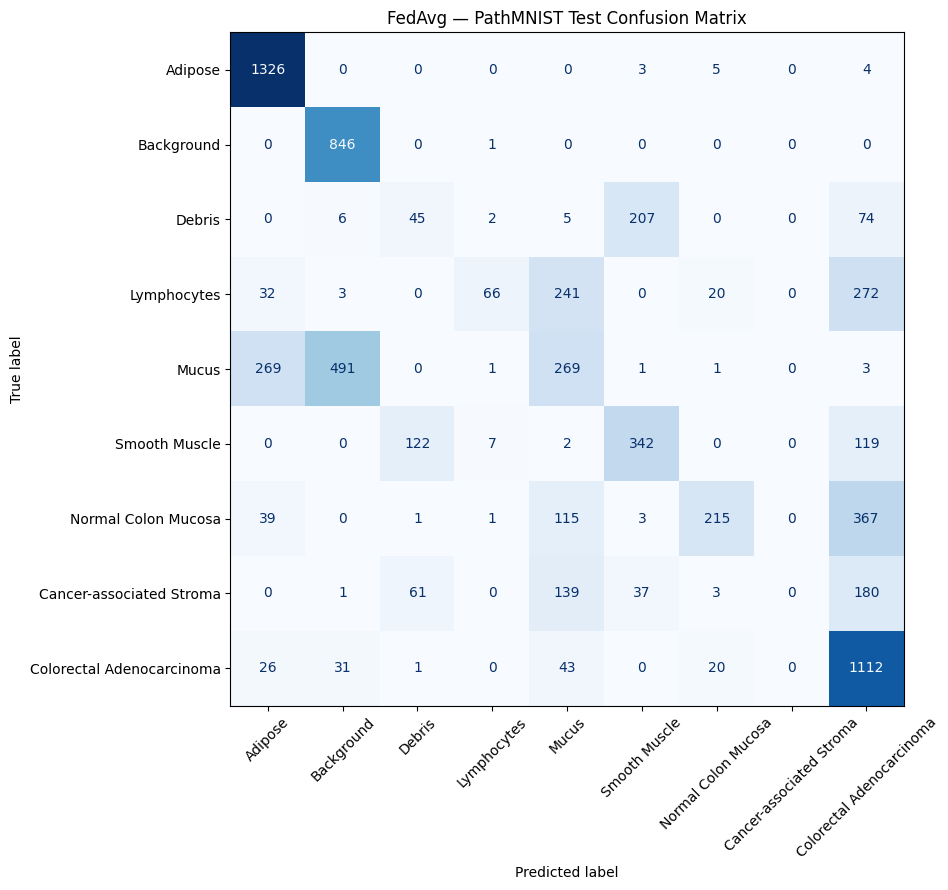

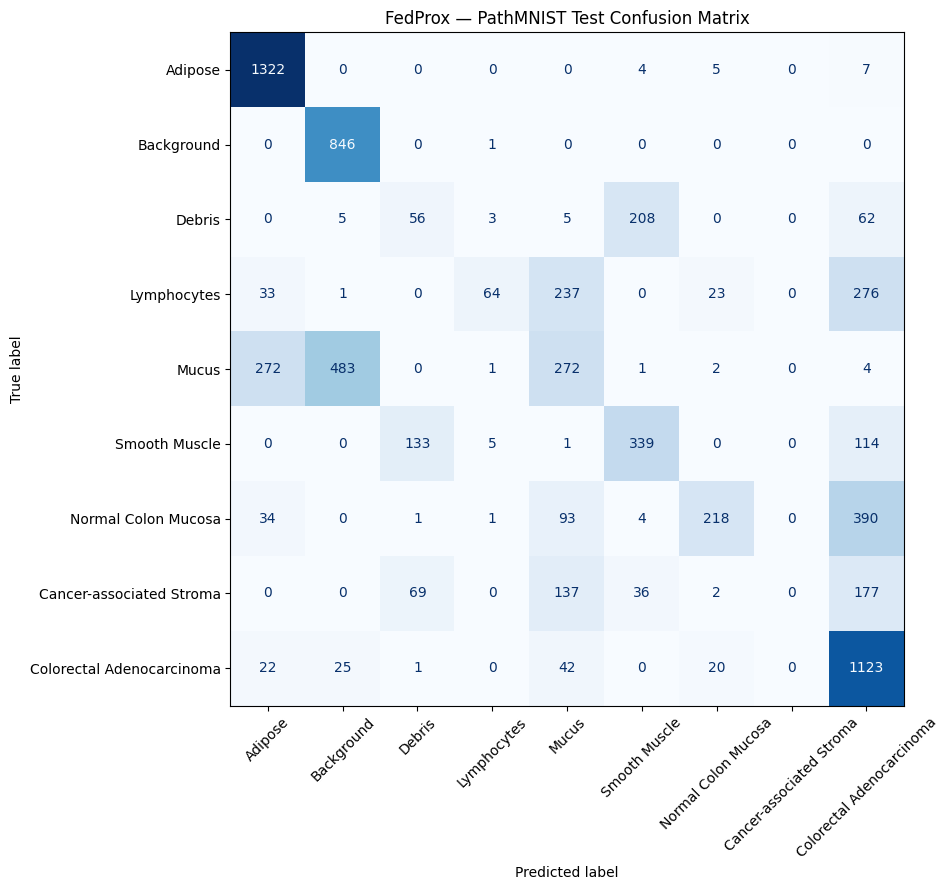

In [65]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(9))
    )

    fig, ax = plt.subplots(figsize=(11, 9))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    display.plot(
        ax=ax,
        xticks_rotation=45,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(title)
    plt.tight_layout()
    plt.show()


plot_confusion_matrix(
    fedavg_y_true,
    fedavg_y_pred,
    "FedAvg — PathMNIST Test Confusion Matrix"
)

plot_confusion_matrix(
    fedprox_y_true,
    fedprox_y_pred,
    "FedProx — PathMNIST Test Confusion Matrix"
)

In [66]:
from collections import Counter
import numpy as np

def prediction_distribution(y_true, y_pred, algorithm):

    true_counts = Counter(y_true)
    pred_counts = Counter(y_pred)

    print(f"\n{'='*65}")
    print(f"{algorithm}: TRUE VS PREDICTED CLASS DISTRIBUTION")
    print(f"{'='*65}")

    print(
        f"{'Class':<30}"
        f"{'True Count':>12}"
        f"{'Predicted':>12}"
        f"{'Difference':>12}"
    )

    for class_id, class_name in enumerate(CLASS_NAMES):

        true_count = true_counts.get(class_id, 0)
        predicted_count = pred_counts.get(class_id, 0)

        print(
            f"{class_name:<30}"
            f"{true_count:>12}"
            f"{predicted_count:>12}"
            f"{predicted_count-true_count:>12}"
        )


prediction_distribution(
    fedavg_y_true,
    fedavg_y_pred,
    "FedAvg"
)

prediction_distribution(
    fedprox_y_true,
    fedprox_y_pred,
    "FedProx"
)


FedAvg: TRUE VS PREDICTED CLASS DISTRIBUTION
Class                           True Count   Predicted  Difference
Adipose                               1338        1692         354
Background                             847        1378         531
Debris                                 339         230        -109
Lymphocytes                            634          78        -556
Mucus                                 1035         814        -221
Smooth Muscle                          592         593           1
Normal Colon Mucosa                    741         264        -477
Cancer-associated Stroma               421           0        -421
Colorectal Adenocarcinoma             1233        2131         898

FedProx: TRUE VS PREDICTED CLASS DISTRIBUTION
Class                           True Count   Predicted  Difference
Adipose                               1338        1683         345
Background                             847        1360         513
Debris                              

In [67]:
# Evaluate FedAvg on Client 3's clean test subset
client3_y_true, client3_fedavg_pred = collect_predictions(
    fedavg_model,
    client_test_loaders[3],
    device
)

# Evaluate FedProx on Client 3's clean test subset
_, client3_fedprox_pred = collect_predictions(
    fedprox_model,
    client_test_loaders[3],
    device
)

prediction_distribution(
    client3_y_true,
    client3_fedavg_pred,
    "FedAvg - Client 3"
)

prediction_distribution(
    client3_y_true,
    client3_fedprox_pred,
    "FedProx - Client 3"
)


FedAvg - Client 3: TRUE VS PREDICTED CLASS DISTRIBUTION
Class                           True Count   Predicted  Difference
Adipose                                  0         203         203
Background                               0         378         378
Debris                                 174         111         -63
Lymphocytes                            164          17        -147
Mucus                                  765         396        -369
Smooth Muscle                          161         239          78
Normal Colon Mucosa                     83          33         -50
Cancer-associated Stroma               377           0        -377
Colorectal Adenocarcinoma                0         347         347

FedProx - Client 3: TRUE VS PREDICTED CLASS DISTRIBUTION
Class                           True Count   Predicted  Difference
Adipose                                  0         207         207
Background                               0         367         367
Debris        

In [68]:
import numpy as np
import pandas as pd

training_distribution = []

for cid in range(5):
    labels = np.asarray(client_train_labels[cid])

    counts = np.bincount(labels, minlength=9)

    training_distribution.append(counts)

training_df = pd.DataFrame(
    training_distribution,
    columns=CLASS_NAMES,
    index=[f"Client {i}" for i in range(5)]
)

training_df["Total"] = training_df.sum(axis=1)

print("CLIENT TRAINING CLASS DISTRIBUTION")
display(training_df)

print("\nGLOBAL CLASS DISTRIBUTION")

global_distribution = training_df[CLASS_NAMES].sum(axis=0)

global_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Training Samples": global_distribution.values,
    "Percentage": (
        global_distribution.values /
        global_distribution.sum() * 100
    ).round(2)
})

display(global_df)

CLIENT TRAINING CLASS DISTRIBUTION


,Adipose,Background,Debris,Lymphocytes,Mucus,Smooth Muscle,Normal Colon Mucosa,Cancer-associated Stroma,Colorectal Adenocarcinoma,Total
Client 0,1295,1023,1246,5371,1155,5318,1325,1007,2585,20325
Client 1,2902,7312,7688,6,264,408,4539,42,1070,24231
Client 2,819,1597,220,1765,69,670,0,8763,13,13916
Client 3,4713,79,22,179,7148,15,2709,2,8882,23749
Client 4,451,441,2051,515,204,3237,86,594,196,7775



GLOBAL CLASS DISTRIBUTION


,Class,Training Samples,Percentage
0,Adipose,10180,11.31
1,Background,10452,11.61
2,Debris,11227,12.47
3,Lymphocytes,7836,8.71
4,Mucus,8840,9.82
5,Smooth Muscle,9648,10.72
6,Normal Colon Mucosa,8659,9.62
7,Cancer-associated Stroma,10408,11.56
8,Colorectal Adenocarcinoma,12746,14.16


In [69]:
for cid in range(5):
    print(
        f"Client {cid}: "
        f"Samples={len(client_train_labels[cid])}, "
        f"Changed labels={client_noise_masks[cid].sum()}"
    )

Client 0: Samples=20325, Changed labels=8130
Client 1: Samples=24231, Changed labels=0
Client 2: Samples=13916, Changed labels=0
Client 3: Samples=23749, Changed labels=0
Client 4: Samples=7775, Changed labels=0


In [70]:
import numpy as np
import pandas as pd

# Rows = clients, columns = classes
counts = training_df[CLASS_NAMES].to_numpy()

# Calculate each client's share of each global class
class_totals = counts.sum(axis=0)

client_class_share = (
    counts / class_totals[np.newaxis, :]
) * 100

share_df = pd.DataFrame(
    client_class_share,
    columns=CLASS_NAMES,
    index=[f"Client {i}" for i in range(5)]
)

print("CLIENT SHARE OF EACH GLOBAL CLASS (%)")
display(share_df.round(2))

# Calculate concentration using Herfindahl-Hirschman Index
hhi = np.sum((client_class_share / 100) ** 2, axis=0)

concentration_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "HHI": hhi,
    "Effective Client Count": 1 / hhi
})

print("\nCLASS CONCENTRATION")
display(concentration_df.round(3))

CLIENT SHARE OF EACH GLOBAL CLASS (%)


,Adipose,Background,Debris,Lymphocytes,Mucus,Smooth Muscle,Normal Colon Mucosa,Cancer-associated Stroma,Colorectal Adenocarcinoma
Client 0,12.72,9.79,11.10,68.54,13.07,55.12,15.30,9.68,20.28
Client 1,28.51,69.96,68.48,0.08,2.99,4.23,52.42,0.40,8.39
Client 2,8.05,15.28,1.96,22.52,0.78,6.94,0.00,84.19,0.10
Client 3,46.30,0.76,0.20,2.28,80.86,0.16,31.29,0.02,69.68
Client 4,4.43,4.22,18.27,6.57,2.31,33.55,0.99,5.71,1.54



CLASS CONCENTRATION


,Class,HHI,Effective Client Count
0,Adipose,0.320,3.123
1,Background,0.524,1.908
2,Debris,0.515,1.942
3,Lymphocytes,0.525,1.903
4,Mucus,0.672,1.487
5,Smooth Muscle,0.423,2.364
6,Normal Colon Mucosa,0.396,2.524
7,Cancer-associated Stroma,0.722,1.386
8,Colorectal Adenocarcinoma,0.534,1.873


In [71]:
print("client_results exists:", "client_results" in globals())

if "client_results" in globals():
    print("Number of client models:", len(client_results))
    print("Available clients:", list(client_results.keys()))

client_results exists: True
Number of client models: 5
Available clients: [0, 1, 2, 3, 4]


In [72]:
for cid, result in client_results.items():
    print(
        f"Client {cid}:",
        "Model available =", "model" in result
    )

Client 0: Model available = True
Client 1: Model available = True
Client 2: Model available = True
Client 3: Model available = True
Client 4: Model available = True


In [73]:
import pandas as pd
import numpy as np

local_model_results = []

for cid in range(5):

    local_model = client_results[cid]["model"]

    y_true, y_pred = collect_predictions(
        local_model,
        client_test_loaders[cid],
        device
    )

    accuracy = (y_true == y_pred).mean()

    local_model_results.append({
        "Client": cid,
        "Test Samples": len(y_true),
        "Local Model Accuracy": accuracy,
        "Correct Predictions": int((y_true == y_pred).sum()),
        "Incorrect Predictions": int((y_true != y_pred).sum())
    })

local_results_df = pd.DataFrame(local_model_results)

print("FEDAVG LOCAL MODEL PERFORMANCE")
display(local_results_df.round(4))

FEDAVG LOCAL MODEL PERFORMANCE


,Client,Test Samples,Local Model Accuracy,Correct Predictions,Incorrect Predictions
0,0,2080,0.0034,7,2073
1,1,791,0.0025,2,789
2,2,1915,0.0016,3,1912
3,3,1724,0.4437,765,959
4,4,670,0.0119,8,662


In [74]:
print("Current algorithm:", algorithm if "algorithm" in globals() else "Not available")

print("Client result keys:", list(client_results[0].keys()))

print("Number of stored client models:", len(client_results))

Current algorithm: Not available
Client result keys: ['model', 'classification_loss', 'objective_loss']
Number of stored client models: 5


In [75]:
import torch
import copy

def calculate_parameter_distance(model_a, model_b):
    squared_distance = 0.0
    squared_norm_a = 0.0

    for p_a, p_b in zip(
        model_a.parameters(),
        model_b.parameters()
    ):
        squared_distance += torch.sum(
            (p_a.detach() - p_b.detach()) ** 2
        ).item()

        squared_norm_a += torch.sum(
            p_a.detach() ** 2
        ).item()

    return (
        squared_distance ** 0.5,
        (squared_distance / (squared_norm_a + 1e-12)) ** 0.5
    )


print("LOCAL MODEL DISTANCE FROM FINAL FEDAVG GLOBAL MODEL")
print("-" * 65)

for cid in range(5):

    local_model = client_results[cid]["model"]

    absolute_distance, relative_distance = calculate_parameter_distance(
        local_model,
        fedavg_model
    )

    print(
        f"Client {cid}: "
        f"Absolute distance = {absolute_distance:.6f}, "
        f"Relative distance = {relative_distance:.6f}"
    )

LOCAL MODEL DISTANCE FROM FINAL FEDAVG GLOBAL MODEL
-----------------------------------------------------------------
Client 0: Absolute distance = 12.872370, Relative distance = 2.157061
Client 1: Absolute distance = 12.902646, Relative distance = 2.110913
Client 2: Absolute distance = 12.898353, Relative distance = 2.134500
Client 3: Absolute distance = 12.954823, Relative distance = 2.116134
Client 4: Absolute distance = 12.876930, Relative distance = 2.151075


In [76]:
print("VERIFYING GLOBAL MODEL PERFORMANCE ON CLIENT TEST SETS")
print("-" * 60)

for cid in range(5):

    loss, accuracy = evaluate(
        fedavg_model,
        client_test_loaders[cid],
        criterion,
        device
    )

    print(
        f"Client {cid}: "
        f"Loss = {loss:.4f}, "
        f"Accuracy = {accuracy * 100:.2f}%"
    )

VERIFYING GLOBAL MODEL PERFORMANCE ON CLIENT TEST SETS
------------------------------------------------------------
Client 0: Loss = 0.5692, Accuracy = 77.84%
Client 1: Loss = 0.8787, Accuracy = 68.39%
Client 2: Loss = 1.2151, Accuracy = 67.73%
Client 3: Loss = 2.0193, Accuracy = 20.01%
Client 4: Loss = 1.0485, Accuracy = 62.54%


In [77]:
# Find notebook cells that reference client_results

for i, cell in enumerate(In):
    if "client_results" in cell:
        print(f"\n{'=' * 60}")
        print(f"Notebook execution cell: {i}")
        print(cell[:2000])



Notebook execution cell: 33
import copy

def fedavg_aggregation(client_results, client_indices):

    total_samples = sum(
        len(client_indices[client_id])
        for client_id in client_results
    )

    global_state = {}

    for key in client_results[0]["model"].state_dict():

        global_state[key] = torch.zeros_like(
            client_results[0]["model"].state_dict()[key]
        )

        for client_id, result in client_results.items():

            client_weight = (
                len(client_indices[client_id]) / total_samples
            )

            client_parameter = (
                result["model"].state_dict()[key]
            )

            global_state[key] += (
                client_weight * client_parameter
            )

    return global_state

Notebook execution cell: 34
client_results = {}

for client_id in range(NUM_CLIENTS):

    result = train_client(
        global_model=global_model,
        train_loader=client_loaders[client_id],
        dev

In [78]:
print("FedAvg global model:", type(fedavg_model))
print("FedProx global model:", type(fedprox_model))

print("\nStored local models:")
for cid in range(5):
    print(
        cid,
        type(client_results[cid]["model"]),
        client_results[cid]["model"].training
    )

FedAvg global model: <class '__main__.PathMNISTCNN'>
FedProx global model: <class '__main__.PathMNISTCNN'>

Stored local models:
0 <class '__main__.PathMNISTCNN'> False
1 <class '__main__.PathMNISTCNN'> False
2 <class '__main__.PathMNISTCNN'> False
3 <class '__main__.PathMNISTCNN'> False
4 <class '__main__.PathMNISTCNN'> False


In [79]:
import inspect

print("FEDERATED EXPERIMENT FUNCTION")
print("=" * 65)

print(inspect.getsource(run_federated_experiment))

FEDERATED EXPERIMENT FUNCTION
def run_federated_experiment(
    algorithm,
    initial_state,
    rounds=1,
    local_epochs=2,
    learning_rate=0.01,
    mu=0.01,
    seed=42
):

    if algorithm not in ["fedavg", "fedprox"]:
        raise ValueError("Algorithm must be fedavg or fedprox")

    # Reset random generators for a reproducible comparison
    set_seed(seed)

    # Fresh global model initialized from the common state
    server_model = PathMNISTCNN(num_classes=9).to(device)
    server_model.load_state_dict(copy.deepcopy(initial_state))

    history = []

    print(f"\nStarting {algorithm.upper()} experiment")
    print(f"Communication rounds: {rounds}")

    for round_num in range(1, rounds + 1):

        print(f"\n{'=' * 45}")
        print(f"{algorithm.upper()} | Round {round_num}")
        print(f"{'=' * 45}")

        # Preserve the global model at the beginning of the round
        round_start_model = copy.deepcopy(server_model)

        client_results = {}

        # -

In [80]:
print("NOTEBOOK HISTORY SUMMARY")
print("=" * 65)

for i, cell in enumerate(In):
    if any(term in cell for term in [
        "client_results =",
        "client_results[",
        "run_federated_experiment("
    ]):
        print(f"\nCell {i}:")
        print(cell[:1500])

NOTEBOOK HISTORY SUMMARY

Cell 33:
import copy

def fedavg_aggregation(client_results, client_indices):

    total_samples = sum(
        len(client_indices[client_id])
        for client_id in client_results
    )

    global_state = {}

    for key in client_results[0]["model"].state_dict():

        global_state[key] = torch.zeros_like(
            client_results[0]["model"].state_dict()[key]
        )

        for client_id, result in client_results.items():

            client_weight = (
                len(client_indices[client_id]) / total_samples
            )

            client_parameter = (
                result["model"].state_dict()[key]
            )

            global_state[key] += (
                client_weight * client_parameter
            )

    return global_state

Cell 34:
client_results = {}

for client_id in range(NUM_CLIENTS):

    result = train_client(
        global_model=global_model,
        train_loader=client_loaders[client_id],
        device=device,
 

In [81]:
required_objects = [
    "initial_state",
    "fedavg_model",
    "fedavg_history",
    "fedprox_model",
    "fedprox_history",
    "client_loaders",
    "client_indices",
    "client_test_loaders"
]

print("EXPERIMENT ARTIFACT CHECK")
print("=" * 45)

for name in required_objects:
    exists = name in globals()
    print(f"{name:25s}: {'AVAILABLE' if exists else 'MISSING'}")

print("\nFedAvg history rounds:", len(fedavg_history))
print("FedProx history rounds:", len(fedprox_history))
print("Number of client loaders:", len(client_loaders))

EXPERIMENT ARTIFACT CHECK
initial_state            : AVAILABLE
fedavg_model             : AVAILABLE
fedavg_history           : AVAILABLE
fedprox_model            : AVAILABLE
fedprox_history          : AVAILABLE
client_loaders           : AVAILABLE
client_indices           : AVAILABLE
client_test_loaders      : AVAILABLE

FedAvg history rounds: 40
FedProx history rounds: 40
Number of client loaders: 5


In [82]:
import copy
import torch

# Preserve the original model state for comparison
original_fedavg_state = {
    key: value.detach().cpu().clone()
    for key, value in fedavg_model.state_dict().items()
}

print("Original FedAvg model preserved.")
print("Parameters:", sum(
    p.numel() for p in fedavg_model.parameters()
))

print("Final recorded FedAvg validation accuracy:",
      fedavg_history[-1]["global_val_accuracy"])

print("Final recorded FedAvg validation loss:",
      fedavg_history[-1]["global_val_loss"])

Original FedAvg model preserved.
Parameters: 19977
Final recorded FedAvg validation accuracy: 0.516593362654938
Final recorded FedAvg validation loss: 1.3027842769333002


In [83]:
import copy
import torch
import torch.nn.functional as F

def run_fedavg_with_local_checkpoints(
    initial_state,
    rounds=40,
    local_epochs=2,
    learning_rate=0.01,
    seed=42
):
    set_seed(seed)

    diagnostic_server = PathMNISTCNN(num_classes=9).to(device)
    diagnostic_server.load_state_dict(copy.deepcopy(initial_state))

    final_round_client_results = None
    diagnostic_history = []

    for round_num in range(1, rounds + 1):

        round_start_model = copy.deepcopy(diagnostic_server)
        client_results_round = {}

        for cid in range(NUM_CLIENTS):

            result = train_client(
                global_model=round_start_model,
                train_loader=client_loaders[cid],
                device=device,
                algorithm="fedavg",
                local_epochs=local_epochs,
                learning_rate=learning_rate
            )

            client_results_round[cid] = result

        aggregated_state = fedavg_aggregation(
            client_results_round,
            client_indices
        )

        diagnostic_server.load_state_dict(aggregated_state)

        val_loss, val_accuracy = evaluate(
            diagnostic_server,
            val_loader,
            criterion,
            device
        )

        diagnostic_history.append({
            "round": round_num,
            "global_val_loss": val_loss,
            "global_val_accuracy": val_accuracy
        })

        if round_num == rounds:
            final_round_client_results = {
                cid: {
                    "model": copy.deepcopy(result["model"]).cpu(),
                    "classification_loss": result["classification_loss"],
                    "objective_loss": result["objective_loss"]
                }
                for cid, result in client_results_round.items()
            }

        if round_num % 10 == 0 or round_num == 1:
            print(
                f"Round {round_num:02d}/{rounds} | "
                f"Validation Loss: {val_loss:.4f} | "
                f"Validation Accuracy: {val_accuracy:.4f}"
            )

    return (
        diagnostic_server,
        diagnostic_history,
        final_round_client_results
    )

In [84]:
diagnostic_fedavg_model, diagnostic_fedavg_history, final_round_local_models = (
    run_fedavg_with_local_checkpoints(
        initial_state=initial_state,
        rounds=40,
        local_epochs=2,
        learning_rate=0.01,
        seed=42
    )
)

Round 01/40 | Validation Loss: 2.2360 | Validation Accuracy: 0.2360
Round 10/40 | Validation Loss: 1.7905 | Validation Accuracy: 0.3305
Round 20/40 | Validation Loss: 1.4936 | Validation Accuracy: 0.4733
Round 30/40 | Validation Loss: 1.4422 | Validation Accuracy: 0.4746
Round 40/40 | Validation Loss: 1.4897 | Validation Accuracy: 0.4559


In [85]:
import torch
import numpy as np

# Compare original and reproduced global model parameters
max_abs_difference = 0.0
squared_difference = 0.0
squared_original_norm = 0.0

for key, original_tensor in original_fedavg_state.items():

    reproduced_tensor = (
        diagnostic_fedavg_model.state_dict()[key]
        .detach()
        .cpu()
    )

    difference = original_tensor - reproduced_tensor

    max_abs_difference = max(
        max_abs_difference,
        difference.abs().max().item()
    )

    squared_difference += difference.pow(2).sum().item()
    squared_original_norm += original_tensor.pow(2).sum().item()

relative_difference = (
    squared_difference / (squared_original_norm + 1e-12)
) ** 0.5

print("GLOBAL MODEL REPRODUCIBILITY")
print("=" * 45)
print(f"Maximum absolute parameter difference: {max_abs_difference:.10f}")
print(f"Relative parameter difference:         {relative_difference:.10f}")

# Compare validation accuracy at selected rounds
print("\nVALIDATION ACCURACY COMPARISON")
print("-" * 55)

for round_num in [1, 5, 10, 20, 30, 35, 40]:

    original_acc = fedavg_history[round_num - 1]["global_val_accuracy"]
    reproduced_acc = diagnostic_fedavg_history[round_num - 1]["global_val_accuracy"]

    print(
        f"Round {round_num:02d} | "
        f"Original: {original_acc:.4f} | "
        f"Reproduced: {reproduced_acc:.4f} | "
        f"Difference: {reproduced_acc - original_acc:+.4f}"
    )

GLOBAL MODEL REPRODUCIBILITY
Maximum absolute parameter difference: 0.1083304733
Relative parameter difference:         0.0262934061

VALIDATION ACCURACY COMPARISON
-------------------------------------------------------
Round 01 | Original: 0.2360 | Reproduced: 0.2360 | Difference: +0.0000
Round 05 | Original: 0.2371 | Reproduced: 0.2431 | Difference: +0.0060
Round 10 | Original: 0.3407 | Reproduced: 0.3305 | Difference: -0.0102
Round 20 | Original: 0.4705 | Reproduced: 0.4733 | Difference: +0.0028
Round 30 | Original: 0.4733 | Reproduced: 0.4746 | Difference: +0.0013
Round 35 | Original: 0.4265 | Reproduced: 0.4766 | Difference: +0.0501
Round 40 | Original: 0.5166 | Reproduced: 0.4559 | Difference: -0.0607


In [86]:
import torch
import numpy as np
import random

print("REPRODUCIBILITY SETTINGS")
print("=" * 45)

print("PyTorch deterministic algorithms:",
      torch.are_deterministic_algorithms_enabled())

print("cuDNN benchmark:",
      torch.backends.cudnn.benchmark)

print("cuDNN deterministic:",
      torch.backends.cudnn.deterministic)

print("CUDA available:", torch.cuda.is_available())

print("\nDataLoader configuration")
for cid, loader in enumerate(client_loaders):
    print(
        f"Client {cid}: "
        f"shuffle={loader.sampler.__class__.__name__}, "
        f"num_workers={loader.num_workers}, "
        f"batch_size={loader.batch_size}, "
        f"drop_last={loader.drop_last}"
    )

print("\nSeed function:")
import inspect
print(inspect.getsource(set_seed))

REPRODUCIBILITY SETTINGS
PyTorch deterministic algorithms: False
cuDNN benchmark: False
cuDNN deterministic: False
CUDA available: True

DataLoader configuration


AttributeError: 'int' object has no attribute 'sampler'

In [87]:
print("CLIENT LOADERS STRUCTURE")
print("=" * 50)

print("Type:", type(client_loaders))

if isinstance(client_loaders, dict):
    print("Keys:", list(client_loaders.keys()))

    for cid, loader in client_loaders.items():
        print(f"\nClient {cid}")
        print("Object type:", type(loader))

        if hasattr(loader, "sampler"):
            print("Sampler:", type(loader.sampler).__name__)
            print("Batch size:", loader.batch_size)
            print("Workers:", loader.num_workers)
            print("Drop last:", loader.drop_last)
        else:
            print("Value:", loader)

elif isinstance(client_loaders, (list, tuple)):
    print("Number of entries:", len(client_loaders))

    for cid, loader in enumerate(client_loaders):
        print(f"\nClient {cid}")
        print("Object type:", type(loader))

        if hasattr(loader, "sampler"):
            print("Sampler:", type(loader.sampler).__name__)
            print("Batch size:", loader.batch_size)
            print("Workers:", loader.num_workers)
            print("Drop last:", loader.drop_last)
        else:
            print("Value:", loader)

CLIENT LOADERS STRUCTURE
Type: <class 'dict'>
Keys: [0, 1, 2, 3, 4]

Client 0
Object type: <class 'torch.utils.data.dataloader.DataLoader'>
Sampler: RandomSampler
Batch size: 64
Workers: 2
Drop last: False

Client 1
Object type: <class 'torch.utils.data.dataloader.DataLoader'>
Sampler: RandomSampler
Batch size: 64
Workers: 2
Drop last: False

Client 2
Object type: <class 'torch.utils.data.dataloader.DataLoader'>
Sampler: RandomSampler
Batch size: 64
Workers: 2
Drop last: False

Client 3
Object type: <class 'torch.utils.data.dataloader.DataLoader'>
Sampler: RandomSampler
Batch size: 64
Workers: 2
Drop last: False

Client 4
Object type: <class 'torch.utils.data.dataloader.DataLoader'>
Sampler: RandomSampler
Batch size: 64
Workers: 2
Drop last: False


In [88]:
import inspect

print(inspect.getsource(set_seed))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)



In [89]:
print("DATALOADER GENERATOR INSPECTION")
print("=" * 50)

for cid, loader in client_loaders.items():
    print(f"\nClient {cid}")

    generator = loader.generator

    print("Generator:", generator)

    if generator is not None:
        print("Generator initial seed:", generator.initial_seed())
    else:
        print("Generator initial seed: Not explicitly assigned")

    print("Sampler generator:", loader.sampler.generator)

    if loader.sampler.generator is not None:
        print(
            "Sampler initial seed:",
            loader.sampler.generator.initial_seed()
        )

DATALOADER GENERATOR INSPECTION

Client 0
Generator: None
Generator initial seed: Not explicitly assigned
Sampler generator: None

Client 1
Generator: None
Generator initial seed: Not explicitly assigned
Sampler generator: None

Client 2
Generator: None
Generator initial seed: Not explicitly assigned
Sampler generator: None

Client 3
Generator: None
Generator initial seed: Not explicitly assigned
Sampler generator: None

Client 4
Generator: None
Generator initial seed: Not explicitly assigned
Sampler generator: None


In [90]:
print("CURRENT CUDA / DETERMINISM SETTINGS")
print("=" * 50)

print("Deterministic algorithms:",
      torch.are_deterministic_algorithms_enabled())

print("cuDNN deterministic:",
      torch.backends.cudnn.deterministic)

print("cuDNN benchmark:",
      torch.backends.cudnn.benchmark)

print("CUDA matmul TF32:",
      torch.backends.cuda.matmul.allow_tf32)

print("cuDNN TF32:",
      torch.backends.cudnn.allow_tf32)

CURRENT CUDA / DETERMINISM SETTINGS
Deterministic algorithms: False
cuDNN deterministic: False
cuDNN benchmark: False
CUDA matmul TF32: False
cuDNN TF32: True


In [91]:
print("INITIAL MODEL STATE CHECK")
print("=" * 50)

original_initial_state = initial_state

max_difference = 0.0

for key in original_initial_state:
    current = diagnostic_fedavg_model.state_dict()[key].detach().cpu()
    initial = original_initial_state[key].detach().cpu()

    if current.shape != initial.shape:
        raise ValueError(f"Shape mismatch: {key}")

    # This only verifies that the state is accessible;
    # it is not expected to match after 40 rounds.
    max_difference = max(
        max_difference,
        torch.max(torch.abs(current - initial)).item()
    )

print("Maximum difference between final model and initial state:",
      max_difference)

INITIAL MODEL STATE CHECK
Maximum difference between final model and initial state: 1.3776899576187134


In [92]:
import inspect

print("TRAIN CLIENT IMPLEMENTATION")
print("=" * 60)
print(inspect.getsource(train_client))

print("\nFEDAVG AGGREGATION IMPLEMENTATION")
print("=" * 60)
print(inspect.getsource(fedavg_aggregation))

TRAIN CLIENT IMPLEMENTATION
def train_client(
    global_model,
    train_loader,
    device,
    algorithm="fedavg",
    local_epochs=2,
    learning_rate=0.01,
    mu=0.01
):

    if algorithm not in ["fedavg", "fedprox"]:
        raise ValueError("Unsupported algorithm")

    # Create an independent local copy of the global model.
    local_model = copy.deepcopy(global_model).to(device)

    # Preserve the global parameters for FedProx.
    global_parameters = [
        parameter.detach().clone()
        for parameter in global_model.parameters()
    ]

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        local_model.parameters(),
        lr=learning_rate
    )

    total_classification_loss = 0.0
    total_objective_loss = 0.0
    total_samples = 0

    for epoch in range(local_epochs):

        local_model.train()

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_b

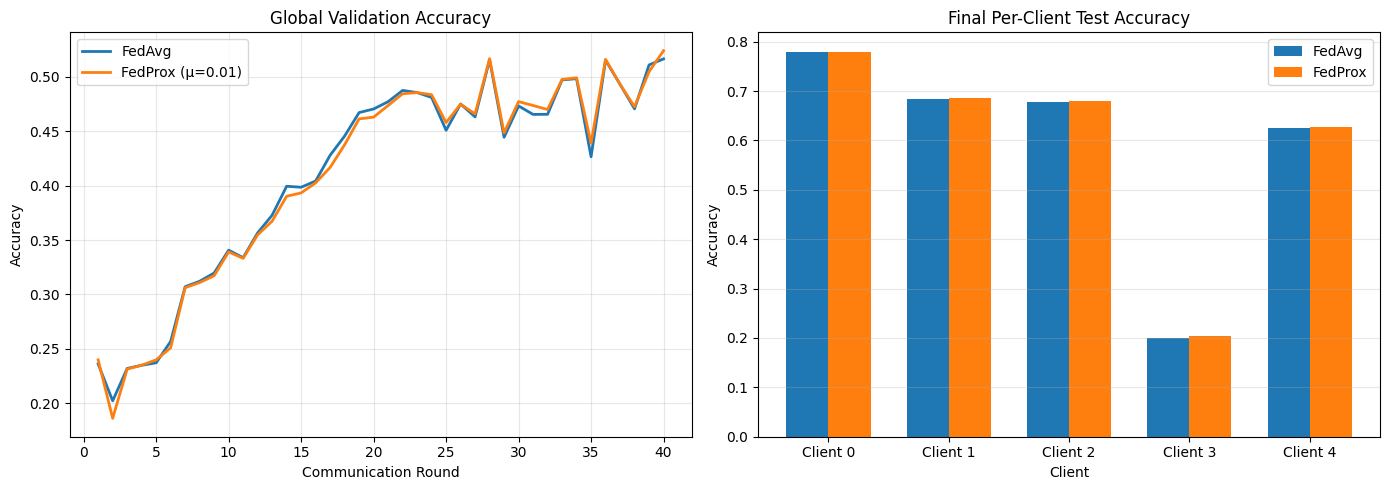

Figure saved successfully.


In [93]:
import matplotlib.pyplot as plt
import numpy as np

# Extract global validation accuracy
rounds = [x["round"] for x in fedavg_history]

fedavg_val_acc = [
    x["global_val_accuracy"] for x in fedavg_history
]

fedprox_val_acc = [
    x["global_val_accuracy"] for x in fedprox_history
]

# Extract final-round per-client test accuracy
clients = list(range(NUM_CLIENTS))

fedavg_client_acc = [
    fedavg_history[-1]["client_test_metrics"][cid]["accuracy"]
    for cid in clients
]

fedprox_client_acc = [
    fedprox_history[-1]["client_test_metrics"][cid]["accuracy"]
    for cid in clients
]

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ------------------------------------------------
# Plot 1: Global validation accuracy
# ------------------------------------------------

axes[0].plot(
    rounds,
    fedavg_val_acc,
    label="FedAvg",
    linewidth=2
)

axes[0].plot(
    rounds,
    fedprox_val_acc,
    label="FedProx (μ=0.01)",
    linewidth=2
)

axes[0].set_title("Global Validation Accuracy")
axes[0].set_xlabel("Communication Round")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ------------------------------------------------
# Plot 2: Per-client test accuracy
# ------------------------------------------------

x = np.arange(NUM_CLIENTS)
width = 0.35

axes[1].bar(
    x - width / 2,
    fedavg_client_acc,
    width,
    label="FedAvg"
)

axes[1].bar(
    x + width / 2,
    fedprox_client_acc,
    width,
    label="FedProx"
)

axes[1].set_title("Final Per-Client Test Accuracy")
axes[1].set_xlabel("Client")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"Client {i}" for i in clients])
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "/content/pathmnist_fedavg_fedprox_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully.")

In [94]:
print("FINAL ROUND ACCURACY COMPARISON")
print("=" * 55)

print(f"{'Client':<12}{'FedAvg':<15}{'FedProx':<15}")

for cid in range(NUM_CLIENTS):
    print(
        f"{cid:<12}"
        f"{fedavg_client_acc[cid]*100:<15.2f}"
        f"{fedprox_client_acc[cid]*100:<15.2f}"
    )

print("\nGlobal validation accuracy:")
print(f"FedAvg : {fedavg_val_acc[-1]*100:.2f}%")
print(f"FedProx: {fedprox_val_acc[-1]*100:.2f}%")

FINAL ROUND ACCURACY COMPARISON
Client      FedAvg         FedProx        
0           77.84          77.98          
1           68.39          68.65          
2           67.73          68.04          
3           20.01          20.42          
4           62.54          62.69          

Global validation accuracy:
FedAvg : 51.66%
FedProx: 52.41%


In [95]:
!pip install -q wandb

In [96]:
import wandb

wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gambee (gambee-thapar-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [97]:
import wandb

WANDB_PROJECT = "pathmnist-federated-learning"

wandb.init(
    project=WANDB_PROJECT,
    name="fedavg_seed42",
    job_type="historical-results-upload",
    config={
        "algorithm": "FedAvg",
        "dataset": "PathMNIST",
        "num_clients": 5,
        "dirichlet_alpha": 0.3,
        "noisy_client": 0,
        "label_noise_rate": 0.40,
        "seed": 42,
        "communication_rounds": 40,
        "local_epochs": 2,
        "batch_size": 64,
        "learning_rate": 0.01,
        "model": "PathMNISTCNN",
        "result_type": "historical_metrics"
    }
)

In [98]:
for record in fedavg_history:

    log_data = {
        "round": record["round"],

        "global/validation_accuracy":
            record["global_val_accuracy"],

        "global/validation_loss":
            record["global_val_loss"],

        "server/aggregate_update_norm":
            record["aggregate_update_norm"]
    }

    for cid in range(NUM_CLIENTS):

        log_data[f"client_{cid}/train_loss"] = (
            record["client_train_loss"][cid]
        )

        log_data[f"client_{cid}/test_accuracy"] = (
            record["client_test_metrics"][cid]["accuracy"]
        )

        log_data[f"client_{cid}/test_loss"] = (
            record["client_test_metrics"][cid]["loss"]
        )

        log_data[f"client_{cid}/update_norm"] = (
            record["client_diagnostics"][cid]["update_norm"]
        )

        log_data[f"client_{cid}/cosine_similarity"] = (
            record["client_diagnostics"][cid]["cosine_similarity"]
        )

    wandb.log(log_data, step=record["round"])

wandb.finish()

print("FedAvg historical metrics uploaded.")

client_0/cosine_similarity,▇▅▅▃▁▄▅▆▇██▇▆▅▅▄▄▄▄▃▃▃▃▃▄▃▃▃▄▃▃▄▄▃▄▃▃▄▄▃
client_0/test_accuracy,▁▁▁▁▃▁▇▇▇▇█▇▇▇█▇▇▇▆██▇▇█▇████▇█▇█▇▇█▇█▇▇
client_0/test_loss,█▇▆▅▅▄▄▄▃▃▂▂▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
client_0/train_loss,█▇▇▇▇▇▆▆▅▄▄▃▃▃▃▂▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
client_0/update_norm,▆▂▁▁▃▄▅▆▇██▇▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▆▇
client_1/cosine_similarity,▆▆▇▆▇███▇▆▆▅▅▅▅▅▅▅▅▅▅▅▅▅▄▄▃▄▃▃▃▂▃▃▁▂▂▂▂▁
client_1/test_accuracy,▁▁▁▂▃▂▂▅▃▅▇▆▆▅▅▅▆▄▄▅▅▄▄▆▄▇▇█▆▅▆▅▇▇▄█▇▇▅▆
client_1/test_loss,█▇▄▃▂▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▂▂▁▂▁▁▂▁▁▁▂▁
client_1/train_loss,█▇▇▆▆▅▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
client_1/update_norm,▇▆▇▅▆██▇▆▅▄▄▃▃▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
+19,...


FedAvg historical metrics uploaded.


In [99]:
wandb.init(
    project=WANDB_PROJECT,
    name="fedprox_mu0.01_seed42",
    job_type="historical-results-upload",
    config={
        "algorithm": "FedProx",
        "mu": 0.01,
        "dataset": "PathMNIST",
        "num_clients": 5,
        "dirichlet_alpha": 0.3,
        "noisy_client": 0,
        "label_noise_rate": 0.40,
        "seed": 42,
        "communication_rounds": 40,
        "local_epochs": 2,
        "batch_size": 64,
        "learning_rate": 0.01,
        "model": "PathMNISTCNN",
        "result_type": "historical_metrics"
    }
)

In [100]:
for record in fedprox_history:

    log_data = {
        "round": record["round"],

        "global/validation_accuracy":
            record["global_val_accuracy"],

        "global/validation_loss":
            record["global_val_loss"],

        "server/aggregate_update_norm":
            record["aggregate_update_norm"]
    }

    for cid in range(NUM_CLIENTS):

        log_data[f"client_{cid}/train_loss"] = (
            record["client_train_loss"][cid]
        )

        log_data[f"client_{cid}/test_accuracy"] = (
            record["client_test_metrics"][cid]["accuracy"]
        )

        log_data[f"client_{cid}/test_loss"] = (
            record["client_test_metrics"][cid]["loss"]
        )

        log_data[f"client_{cid}/update_norm"] = (
            record["client_diagnostics"][cid]["update_norm"]
        )

        log_data[f"client_{cid}/cosine_similarity"] = (
            record["client_diagnostics"][cid]["cosine_similarity"]
        )

    wandb.log(log_data, step=record["round"])

wandb.finish()

print("FedProx historical metrics uploaded.")

client_0/cosine_similarity,▇▅▆▄▁▄▅▆▇███▇▆▅▅▄▄▄▄▄▄▄▃▄▄▄▄▄▃▄▄▄▃▄▄▄▄▄▄
client_0/test_accuracy,▁▁▁▁▂▁▆▇▇▇█▇▇▇█▇▇▇▆██▇▇█▇████▇█▇█▇▇█▇█▇▇
client_0/test_loss,█▇▆▅▅▅▄▄▃▃▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
client_0/train_loss,█▇▇▇▇▇▆▆▅▄▄▃▃▃▃▂▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
client_0/update_norm,▆▂▂▁▃▄▅▆▇██▇▇▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇
client_1/cosine_similarity,▆▆▇▆▆███▇▇▆▅▅▅▅▅▅▅▅▆▅▅▅▅▄▄▃▄▃▃▃▂▃▃▁▃▂▁▂▁
client_1/test_accuracy,▁▁▁▁▃▂▂▅▃▅▆▅▅▅▅▅▆▄▄▅▅▄▃▅▄▇▇█▅▄▆▅▇▆▄▇▆▆▅▆
client_1/test_loss,█▇▅▃▂▂▂▂▂▂▂▂▂▂▂▁▂▂▂▂▂▂▂▁▂▁▁▁▂▁▁▂▁▁▂▁▁▁▂▁
client_1/train_loss,█▇▇▆▆▅▅▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
client_1/update_norm,▇▆▇▅▆██▇▆▅▄▄▄▃▃▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
+19,...


FedProx historical metrics uploaded.


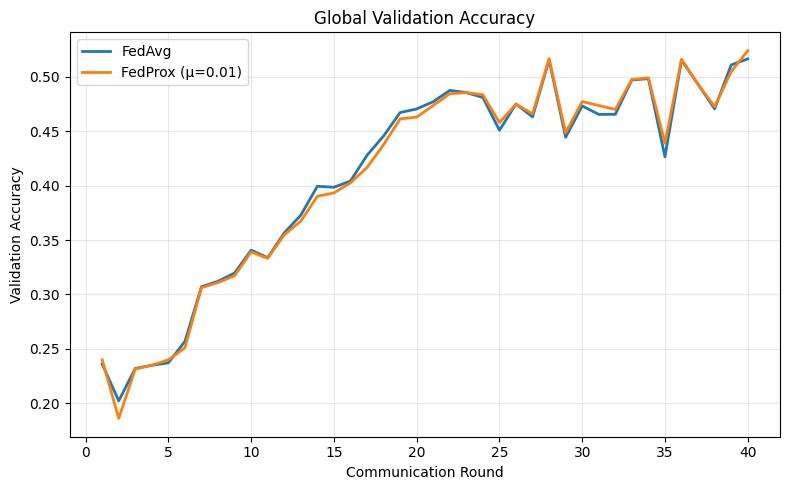

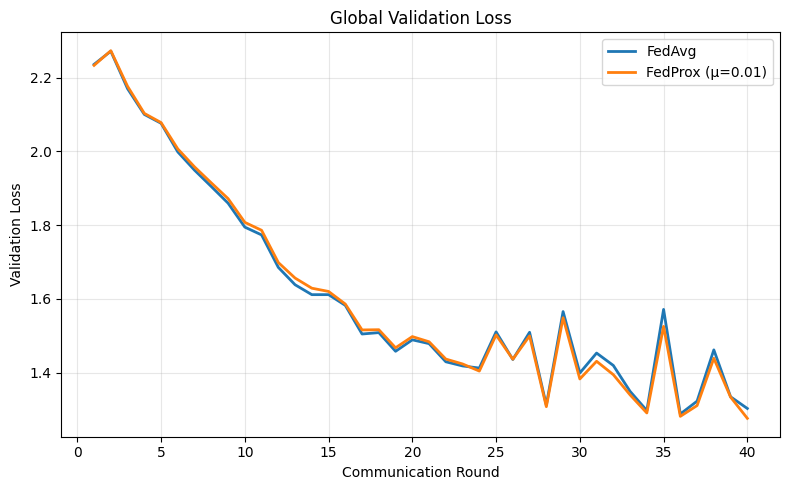

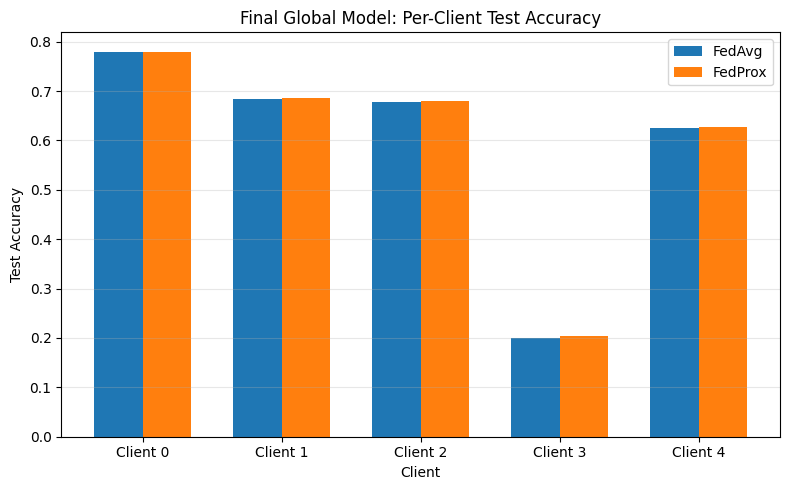

All three figures saved to: /content/PathMNIST-FL/results/figures


In [101]:
import matplotlib.pyplot as plt
import numpy as np
import os

OUTPUT_DIR = "/content/PathMNIST-FL/results/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

rounds = [r["round"] for r in fedavg_history]

# Extract global metrics
fedavg_acc = [r["global_val_accuracy"] for r in fedavg_history]
fedprox_acc = [r["global_val_accuracy"] for r in fedprox_history]

fedavg_loss = [r["global_val_loss"] for r in fedavg_history]
fedprox_loss = [r["global_val_loss"] for r in fedprox_history]

# Extract final-round client metrics
fedavg_client_acc = [
    fedavg_history[-1]["client_test_metrics"][cid]["accuracy"]
    for cid in range(NUM_CLIENTS)
]

fedprox_client_acc = [
    fedprox_history[-1]["client_test_metrics"][cid]["accuracy"]
    for cid in range(NUM_CLIENTS)
]

# Figure 1: Global validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(rounds, fedavg_acc, label="FedAvg", linewidth=2)
plt.plot(rounds, fedprox_acc, label="FedProx (μ=0.01)", linewidth=2)
plt.xlabel("Communication Round")
plt.ylabel("Validation Accuracy")
plt.title("Global Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/global_validation_accuracy.png", dpi=300)
plt.show()

# Figure 2: Global validation loss
plt.figure(figsize=(8, 5))
plt.plot(rounds, fedavg_loss, label="FedAvg", linewidth=2)
plt.plot(rounds, fedprox_loss, label="FedProx (μ=0.01)", linewidth=2)
plt.xlabel("Communication Round")
plt.ylabel("Validation Loss")
plt.title("Global Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/global_validation_loss.png", dpi=300)
plt.show()

# Figure 3: Per-client test accuracy
x = np.arange(NUM_CLIENTS)
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, fedavg_client_acc, width, label="FedAvg")
plt.bar(x + width/2, fedprox_client_acc, width, label="FedProx")
plt.xticks(x, [f"Client {i}" for i in x])
plt.xlabel("Client")
plt.ylabel("Test Accuracy")
plt.title("Final Global Model: Per-Client Test Accuracy")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/per_client_test_accuracy.png", dpi=300)
plt.show()

print("All three figures saved to:", OUTPUT_DIR)

In [102]:
print("FINAL EXPERIMENT SUMMARY")
print("=" * 55)

print(f"FedAvg  | Validation Accuracy: {fedavg_acc[-1]*100:.2f}%")
print(f"FedProx | Validation Accuracy: {fedprox_acc[-1]*100:.2f}%")

print("\nPer-client test accuracy")

for cid in range(NUM_CLIENTS):
    print(
        f"Client {cid}: "
        f"FedAvg = {fedavg_client_acc[cid]*100:.2f}% | "
        f"FedProx = {fedprox_client_acc[cid]*100:.2f}%"
    )

print("\nGenerated files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

FINAL EXPERIMENT SUMMARY
FedAvg  | Validation Accuracy: 51.66%
FedProx | Validation Accuracy: 52.41%

Per-client test accuracy
Client 0: FedAvg = 77.84% | FedProx = 77.98%
Client 1: FedAvg = 68.39% | FedProx = 68.65%
Client 2: FedAvg = 67.73% | FedProx = 68.04%
Client 3: FedAvg = 20.01% | FedProx = 20.42%
Client 4: FedAvg = 62.54% | FedProx = 62.69%

Generated files:
global_validation_accuracy.png
global_validation_loss.png
per_client_test_accuracy.png


In [103]:
import os

PROJECT_DIR = "/content/PathMNIST-FL"

print("PROJECT DIRECTORY")
print("=" * 50)

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)

    if level > 2:
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

PROJECT DIRECTORY
PathMNIST-FL/
    results/
        figures/
            per_client_test_accuracy.png
            global_validation_loss.png
            global_validation_accuracy.png
    data/
        medmnist/
            pathmnist.npz
    artifacts/
        fedprox_final.pth
        client_label_artifacts.npz
        fedavg_final.pth
        fedavg_history.pkl
        fedprox_history.pkl
